In [8]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import stats
from scipy.integrate import quad
from scipy.interpolate import UnivariateSpline, CubicSpline, RegularGridInterpolator, RectBivariateSpline, bisplrep
import seaborn as sns
from scipy.special import factorial
import math
from iminuit import cost, Minuit 
import numpy as np
import pickle

sns.set_context('talk', font_scale=1.0)
sns.set_palette('colorblind')

from depth_helpers import *

Am_line = source_dict['Am241']

# plot_dir = '/home/cosilab/CalibrationData/figures/'
plot_dir = '/Users/Sophie/Desktop/COSI/calibrations/Data/trapping_figures/'
datpath = '/Users/Sophie/Desktop/COSI/calibrations/Data/CalibratedDATs/Am241_2025/'
# datpath = '/home/CalibrationData/CalibratedDATs/'

sim_dCCE_path = '/Users/Sophie/Desktop/COSI/calibrations/Data/SimulatedCSVs/HP41520_1/HP415201_dCCE_1000cm.csv'
sim_dCCE = np.loadtxt(sim_dCCE_path, delimiter=',').T
depth_grid = sim_dCCE[0]

### In these, b=electron trapping, c=hole trapping
def e_cce(b, c):
    ### electron-dominated signal
    return (1.-b*sim_dCCE[1][::-1])*(1.-c*sim_dCCE[2][::-1])
def h_cce(b, c):
    ### hole-dominated signal
    return (1.-b*sim_dCCE[3][::-1])*(1.-c*sim_dCCE[4][::-1])

In [10]:
ecal_path = '/Users/Sophie/Desktop/COSI/calibrations/Data/CalibratedDATs/postLL_2025/recalib/HP41520_EnergyCal_AUG2025_prerad_2.ecal'

# Which ecal side ('h' = high-voltage, 'l' = low-voltage) belongs to the p and n strips in the .dat files.
# CHECK THIS against the detector setup: swapping it applies each strip's gain to the wrong side.
ECAL_SIDE = {'p': 'h', 'n': 'l'}

def read_ecal(path, line_energy=Am_line):
    """
    Parse a Melinator .ecal file.
      CP dss <det> <strip> <h|l> pakw <N> (ADC energy width) x N   -> calibration points
      CM dss <det> <strip> <h|l> poly<k> a0 a1 ... ak               -> E(ADC) = sum a_i ADC^i
    Returns {(strip, side): Am-line energy predicted by the calibration polynomial at the
    measured Am-line ADC}, i.e. the residual of the calibration at line_energy.
    """
    adc_at_line, poly = {}, {}
    with open(path) as f:
        for line in f:
            s = line.split()
            if len(s) < 6 or s[0] not in ('CP', 'CM') or s[1] != 'dss':
                continue
            key = (int(s[3]), s[4])
            if s[0] == 'CP':
                if s[5] != 'pakw':
                    print('Unrecognised CP format, skipping:', line.strip())
                    continue
                n_pts = int(s[6])
                pts = np.array(s[7:7 + 3 * n_pts], dtype=float).reshape(n_pts, 3)  # ADC, energy, width
                k = np.argmin(np.abs(pts[:, 1] - line_energy))
                if np.abs(pts[k, 1] - line_energy) < 0.5:
                    adc_at_line[key] = pts[k, 0]
            else:
                if not s[5].startswith('poly'):
                    print('Unrecognised CM model, skipping:', line.strip())
                    continue
                poly[key] = np.array(s[6:], dtype=float)
    E_at_line = {}
    for key, coeffs in poly.items():
        if key in adc_at_line:
            E_at_line[key] = np.polynomial.polynomial.polyval(adc_at_line[key], coeffs)
    return E_at_line

E_at_line = read_ecal(ecal_path)
strips = sorted({k[0] for k in E_at_line})
strip_offset = 0 if min(strips) == 0 else 1   # ecal strip IDs -> 0-based index
print('ecal strips %d..%d (offset %d), %d entries' % (min(strips), max(strips), strip_offset, len(E_at_line)))

# gain_factor_map[i][strip]: i = 0 for p strips, 1 for n strips (same indexing as the centroid maps)
gain_factor_map = np.ones((2, 37))
for i, side in enumerate(['p', 'n']):
    for (strip, ecal_side), E in E_at_line.items():
        if ecal_side == ECAL_SIDE[side]:
            gain_factor_map[i][strip - strip_offset] = Am_line / E
    print(side, 'gain factor mean %.5f, min %.5f, max %.5f' % (
        gain_factor_map[i].mean(), gain_factor_map[i].min(), gain_factor_map[i].max()))

In [11]:
plt.figure()
plt.plot(range(37), gain_factor_map[0], label='p strips (ecal %s)' % ECAL_SIDE['p'])
plt.plot(range(37), gain_factor_map[1], label='n strips (ecal %s)' % ECAL_SIDE['n'])
plt.xlabel('Strip index')
plt.ylabel('Am-241 gain factor')
plt.legend()
plt.tight_layout()
plt.show()

# Pre LL

In [12]:
files = [["20250404_Am241_AC_1200V_80K.dat", "20251704_Am241_AC_1200V_80K.dat"], \
                      ["20250904_Am241_DC_1200V_80K.dat" ]]

erange = [50., 64.]

emin = erange[0]
emax = erange[1]
bins = int((emax-emin) * 4)

AC_centroid_map = np.zeros((2, 37, 37))
DC_centroid_map = np.zeros_like(AC_centroid_map)

fullpaths = []
for p in files[0]:
    fullpaths.append(datpath +  p)
print(fullpaths)

df_AC = make_df_from_dat(fullpaths, e_min=emin, e_max=emax)

fullpaths = []
for p in files[1]:
    fullpaths.append(datpath + p)

df_DC = make_df_from_dat(fullpaths, e_min=emin, e_max=emax)

print(df_AC.info())

['/Users/Sophie/Desktop/COSI/calibrations/Data/CalibratedDATs/Am241_2025/20250404_Am241_AC_1200V_80K.dat', '/Users/Sophie/Desktop/COSI/calibrations/Data/CalibratedDATs/Am241_2025/20251704_Am241_AC_1200V_80K.dat']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2277716 entries, 0 to 2277715
Data columns (total 13 columns):
 #   Column    Dtype  
---  ------    -----  
 0   ID        int64  
 1   det       int64  
 2   strip_p   int64  
 3   energy_p  float64
 4   time_p    float64
 5   strip_n   int64  
 6   energy_n  float64
 7   time_n    float64
 8   x         float64
 9   y         float64
 10  z         float64
 11  z_err     float64
 12  bad       bool   
dtypes: bool(1), float64(8), int64(4)
memory usage: 210.7 MB
None


In [13]:
##################### PLOTTING CODE TO VISUALIZE LINESHIFTS #########################################
import numpy as np
import matplotlib.pyplot as plt

def plot_photopeak_fit_with_components(
    energies, 
    minuit_fit, 
    pdf_func, 
    component_pdfs=None, 
    n_bins=100, 
    title=None, 
    save_path=None
):
    """
    Plots a binned energy histogram overlaid with an unbinned NLL fit and its sub-components.

    Parameters:
    -----------
    energies : array-like
        Filtered 1D array of energy values used in the fit.
    minuit_fit : iminuit.Minuit
        The fitted Minuit instance post-migrad().
    pdf_func : callable
        Total PDF function, signature: pdf_func(E, **params).
    component_pdfs : dict, optional
        Dictionary mapping component names to their PDF functions, e.g.:
        {'Gaussian': gauss_pdf, 'Low-E Tail': tail_pdf, 'Flat Bkg': bkg_pdf}
        Each function must accept signature: comp_pdf(E, **params).
    n_bins : int, optional
        Number of histogram bins (default 100).
    title : str, optional
        Plot title.
    save_path : str, optional
        File path to save the generated figure.
    """
    if len(energies) == 0:
        print("Warning: No energy data available for plotting.")
        return

    fit_params = minuit_fit.values.to_dict()
    emin = fit_params.get('Emin', energies.min())
    emax = fit_params.get('Emax', energies.max())
    
    # Filter to exact range used during fitting
    valid_mask = (energies >= emin) & (energies <= emax)
    fit_energies = energies[valid_mask]
    total_counts = len(fit_energies)

    fig, ax = plt.subplots(figsize=(8, 5))

    # 1. Binned Data Histogram
    counts, bin_edges, _ = ax.hist(
        fit_energies,
        bins=n_bins,
        range=(emin, emax),
        histtype='step',
        color='black',
        linewidth=1.2,
        label=f'Data ($N={total_counts}$)'
    )

    # 2. Evaluation Grid & Exact Normalization Scale
    bin_width = (emax - emin) / n_bins
    e_eval = np.linspace(emin, emax, 1000)
    
    # Evaluate raw total PDF and re-normalize over [Emin, Emax] grid
    total_pdf_eval = pdf_func(e_eval, **fit_params)
    norm_factor = np.trapz(total_pdf_eval, e_eval)
    
    # Scaled curve for histogram matching: N * bin_width * normalized_pdf
    scaled_total_pdf = (total_pdf_eval / norm_factor) * total_counts * bin_width

    # 3. Plot Total Fit Model
    ax.plot(e_eval, scaled_total_pdf, color='crimson', linewidth=2, label='Total Fit')

    # 4. Plot Individual Components
    if component_pdfs:
        colors = ['dodgerblue', 'darkorange', 'forestgreen', 'purple']
        for idx, (comp_name, comp_fn) in enumerate(component_pdfs.items()):
            comp_eval = comp_fn(e_eval, **fit_params)
            # Scale component relative to the same total integral factor
            scaled_comp = (comp_eval / norm_factor) * total_counts * bin_width
            
            c = colors[idx % len(colors)]
            ax.plot(e_eval, scaled_comp, linestyle='--', color=c, linewidth=1.5, label=comp_name)

    # Annotate centroid and resolution
    x0 = fit_params.get('x0', np.nan)
    sigma = fit_params.get('sigma_gauss', np.nan)
    ax.axvline(x0, color='gray', linestyle=':', alpha=0.8, label=f'$x_0 = {x0:.2f}$ keV')

    ax.set_xlabel('Energy (keV)')
    ax.set_ylabel(f'Counts / ({bin_width:.3f} keV)')
    if title:
        ax.set_title(title)
    ax.legend(frameon=True, loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.5)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()
    plt.close(fig)


# Define component functions matching your PDF parameter names
def gaussian_component(E, x0, sigma_gauss, **kwargs):
    return np.exp(-0.5 * ((E - x0) / sigma_gauss) ** 2) / (sigma_gauss * np.sqrt(2 * np.pi))

def tail_component(E, x0, sigma_gauss, gamma, BoverA, **kwargs):
    # Example tail implementation (adjust to match your exact gauss_minus_linear_tail_pdf logic)
    dx = (E - x0) / sigma_gauss
    return BoverA * np.exp(dx / gamma) * (dx < 0)

def fit_am241_centroid(energies, emin, emax, min_counts=200):
    """
    Unbinned fit of the Am-241 photopeak with gauss_minus_linear_tail_pdf.
    Returns (x0, minuit) or (np.nan, minuit/None) if the fit cannot be trusted,
    so failed pixels are masked downstream instead of being silently kept.
    """
    energies = energies[(energies > emin) & (energies < emax)]
    if len(energies) < min_counts:
        return np.nan, None

    # Start x0 at the histogram maximum instead of a hard-coded 60 keV
    hist, edges = np.histogram(energies, bins=int((emax - emin) * 4), range=(emin, emax))
    centers = 0.5 * (edges[:-1] + edges[1:])
    x0_guess = centers[np.argmax(hist)]

    c = cost.UnbinnedNLL(energies, gauss_minus_linear_tail_pdf)
    m = Minuit(c, BoverA=0.5, x0=x0_guess, sigma_gauss=1.0, gamma=global_gamma,
               CoverB=global_CoverB, D=global_D, sigma_ratio=global_sigma_ratio,
               background=0.01, Emin=emin, Emax=emax)
    m.limits["BoverA", "background"] = (0, None)
    m.limits["sigma_gauss"] = (0.2, 5.0)
    m.limits["x0"] = (max(emin, x0_guess - 3.0), min(emax, x0_guess + 3.0))
    m.fixed["gamma", "CoverB", "D", "sigma_ratio", "Emin", "Emax"] = True
    m.migrad()

    # Reject non-converged fits and fits that never left the starting point
    x0_lo, x0_hi = m.limits['x0']
    if (not m.valid) or (m.values['x0'] == x0_guess) or \
       np.isclose(m.values['x0'], x0_lo, atol=1e-3) or np.isclose(m.values['x0'], x0_hi, atol=1e-3):
        return np.nan, m
    return m.values['x0'], m

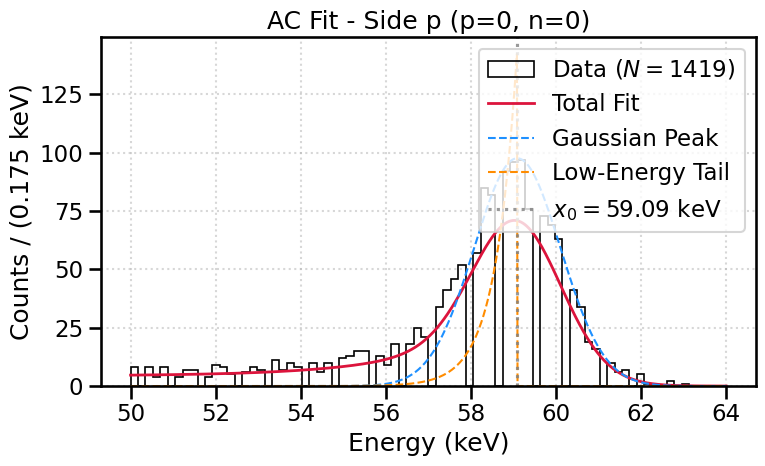

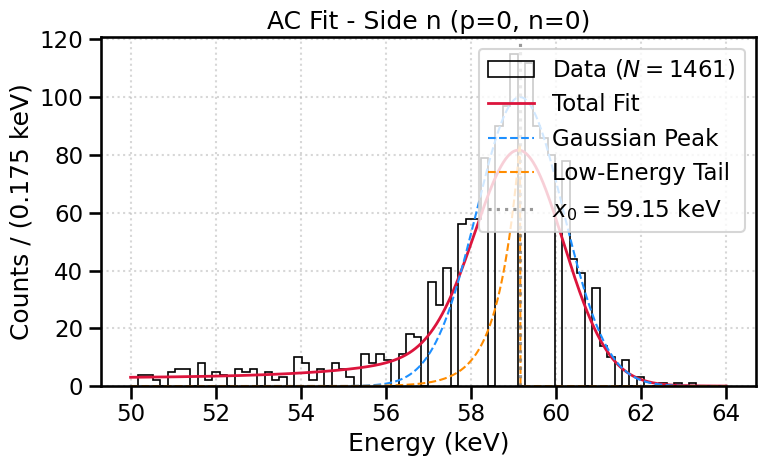

/Users/Sophie/Desktop/COSI/calibrations/Data/depth_helpers.py:78: RuntimeWarning: invalid value encountered in divide
  return gauss_minus_linear_tail_depth(x, 1.0, BoverA, x0, sigma_gauss, gamma, CoverB, D, sigma_ratio, background) / norm
/Users/Sophie/Desktop/COSI/calibrations/Data/depth_helpers.py:70: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  norm, _ = quad(
/Users/Sophie/Desktop/COSI/calibrations/Data/depth_helpers.py:70: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator sho

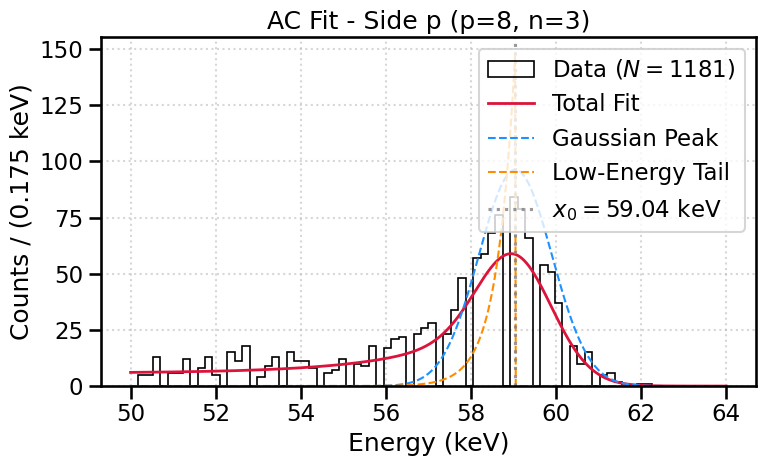

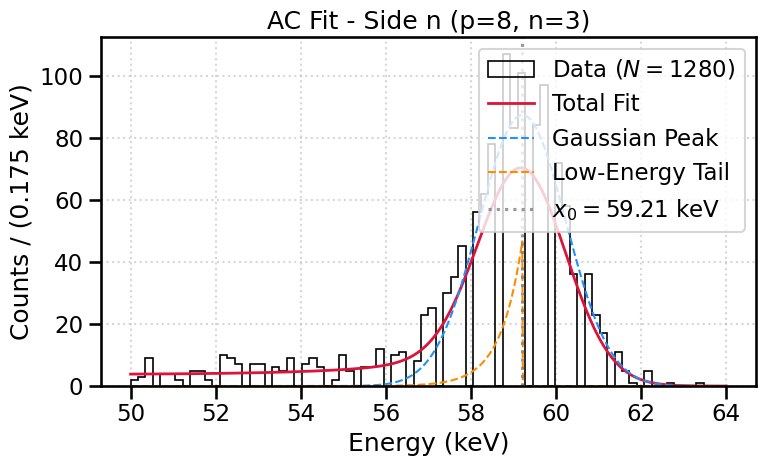

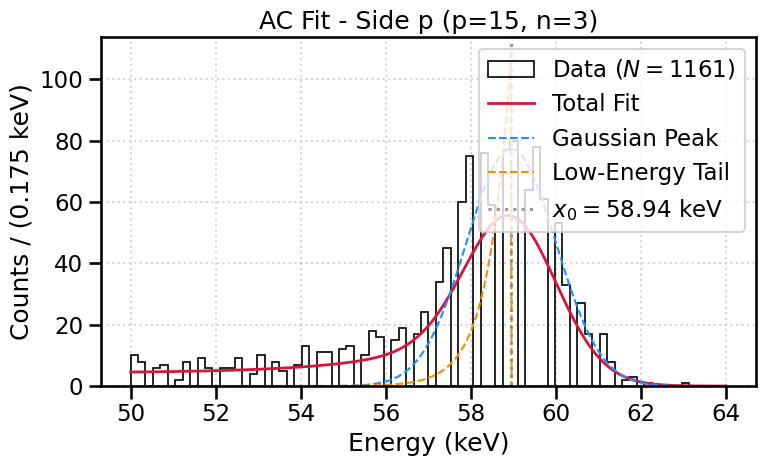

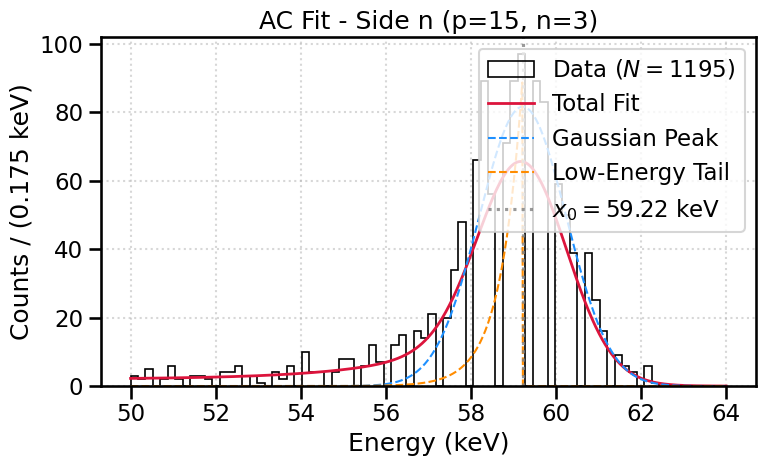

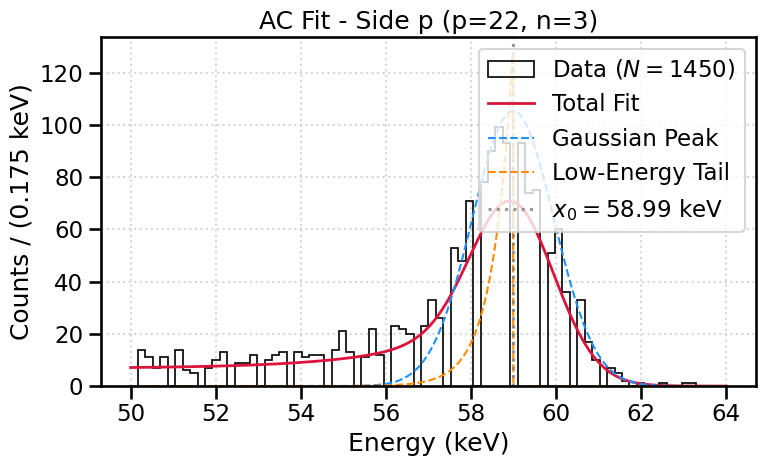

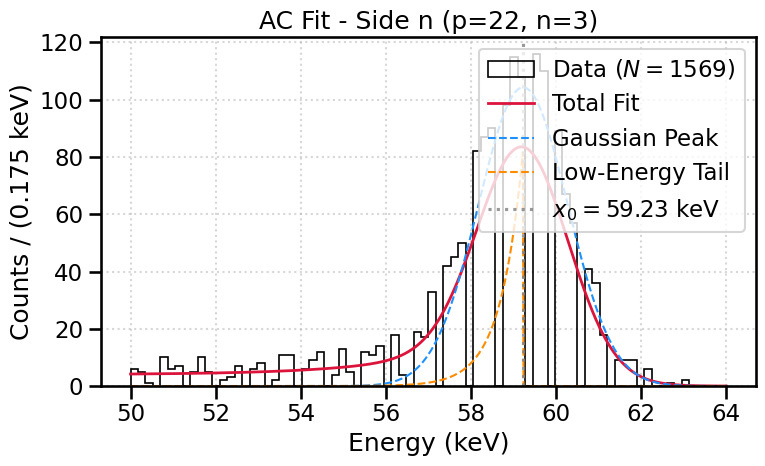

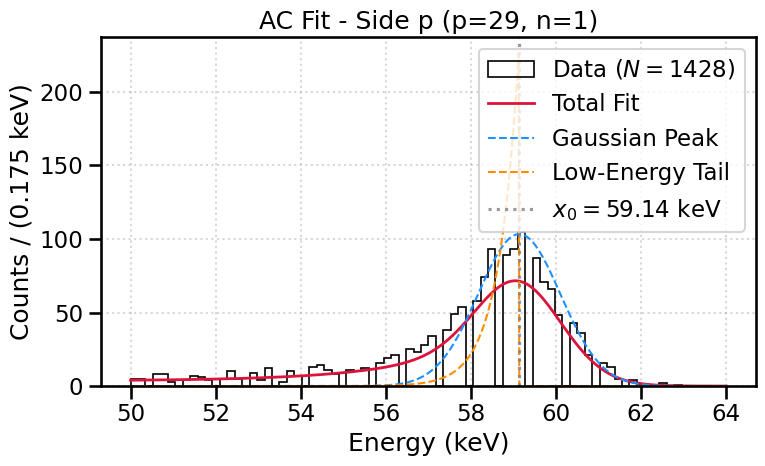

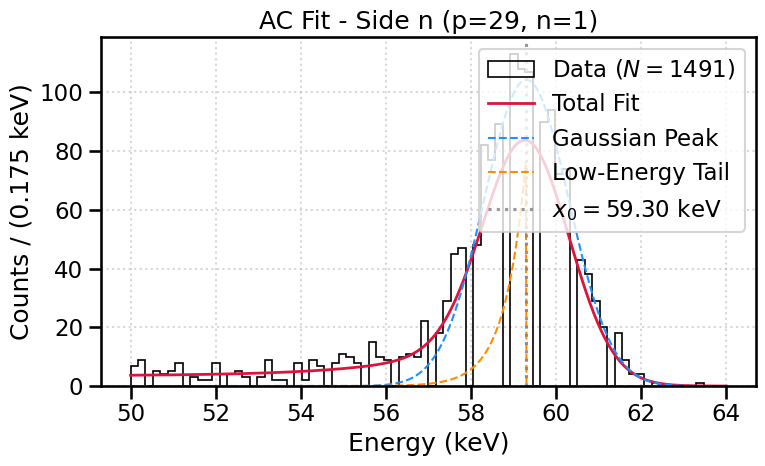

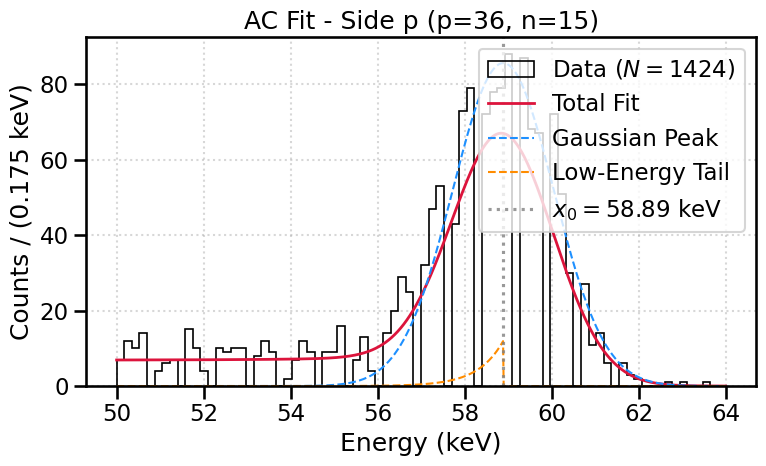

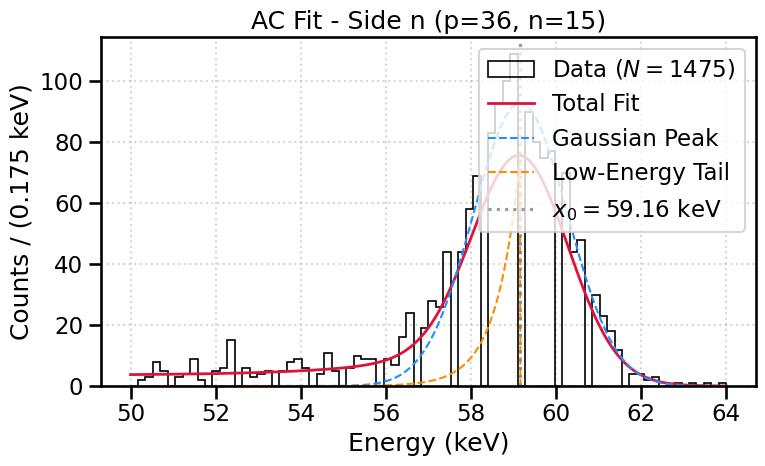

In [14]:
AC_centroid_map = np.full((2, 37, 37), np.nan)
DC_centroid_map = np.full((2, 37, 37), np.nan)
n_failed = {'AC': 0, 'DC': 0}
pixel_counter = 0

for p in range(37):
    for n in range(37):
            # Determine if this pixel should generate fit plots
            should_plot = (pixel_counter % 500 == 0)

            AC_sliced = df_AC.loc[(df_AC['strip_p']==p+1) & (df_AC['strip_n']==n+1)]
            DC_sliced = df_DC.loc[(df_DC['strip_p']==p+1) & (df_DC['strip_n']==n+1)]
            if (len(AC_sliced) > 1000) & (len(DC_sliced) > 1000):

                for i, side in enumerate(['p','n']):
                    gain_factor = gain_factor_map[i][p if side == 'p' else n]

                    x0, m = fit_am241_centroid(AC_sliced['energy_' + side].values, emin, emax)
                    AC_centroid_map[i][p][n] = x0*gain_factor
                    n_failed['AC'] += np.isnan(x0)

                    energies = DC_sliced['energy_' + side].values
                    x0, m = fit_am241_centroid(energies, emin, emax)
                    DC_centroid_map[i][p][n] = x0*gain_factor
                    n_failed['DC'] += np.isnan(x0)

                    if should_plot and m is not None:
                        plot_photopeak_fit_with_components(
                            energies=energies[(energies > emin) & (energies < emax)],
                            minuit_fit=m,
                            pdf_func=gauss_minus_linear_tail_pdf,
                            component_pdfs={
                                'Gaussian Peak': gaussian_component,
                                'Low-Energy Tail': tail_component
                            },
                            n_bins=80,
                            title=f"DC Fit - Side {side} (p={p}, n={n})"
                        )
                pixel_counter += 1

# Sanity checks: a stuck fit used to leave x0 at the 60 keV starting value everywhere
print('Failed fits:', n_failed)
for name, cmap in [('AC', AC_centroid_map), ('DC', DC_centroid_map)]:
    for i, side in enumerate(['p', 'n']):
        print(name, side, 'centroid mean = %.3f, std = %.3f keV' % (np.nanmean(cmap[i]), np.nanstd(cmap[i])))


[[[60. 60. 60. ... 60. 60. 60.]
  [60. 60. 60. ... 60. 60. 60.]
  [60. 60. 60. ... 60. 60.  0.]
  ...
  [60. 60. 60. ... 60. 60. 60.]
  [60. 60. 60. ... 60. 60. 60.]
  [60. 60. 60. ... 60. 60. 60.]]

 [[60. 60. 60. ... 60. 60. 60.]
  [60. 60. 60. ... 60. 60. 60.]
  [60. 60. 60. ... 60. 60.  0.]
  ...
  [60. 60. 60. ... 60. 60. 60.]
  [60. 60. 60. ... 60. 60. 60.]
  [60. 60. 60. ... 60. 60. 60.]]] [[[59.13400611 59.11492297 59.16256636 ... 59.12957078 59.05803547
   59.13103995]
  [59.03743736 59.22520333 59.26008541 ... 59.08735899 59.19803121
   59.17307996]
  [59.33630577 59.31289036 59.24509639 ... 59.34491271 59.27379414
    0.        ]
  ...
  [59.33763097 59.32796914 59.24101934 ... 59.28782008 59.18736906
   59.12057054]
  [59.23808471 59.25739172 59.28165682 ... 59.01900369 59.07523203
   59.19940167]
  [59.23661813 59.23296805 59.20781298 ... 59.0897597  59.26492995
   59.13914085]]

 [[58.75154195 58.95302697 58.72123571 ... 58.75292113 58.720654
   58.20635544]
  [58.7906522

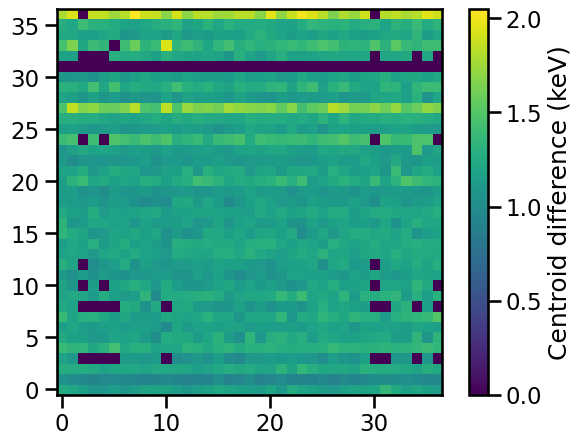

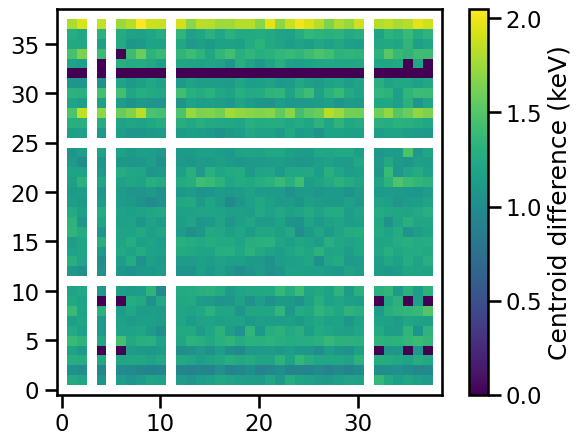

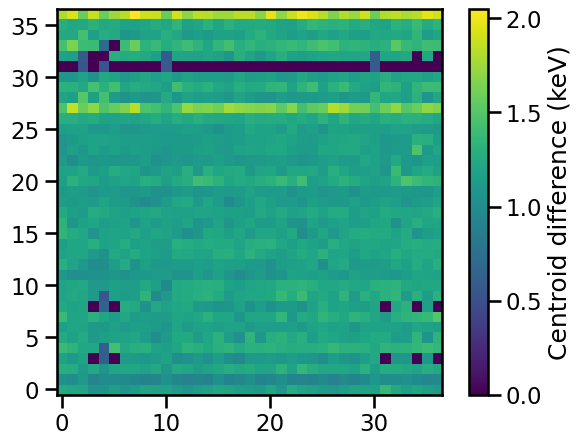

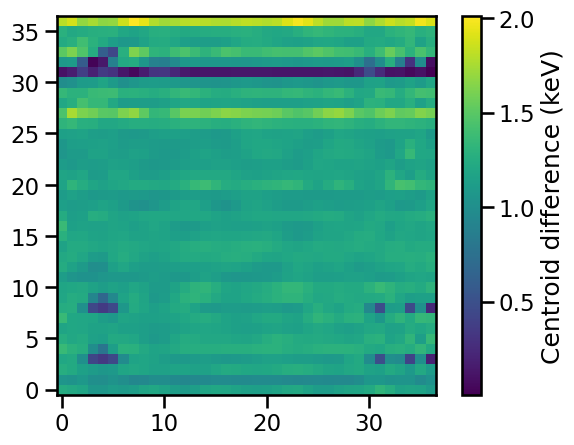

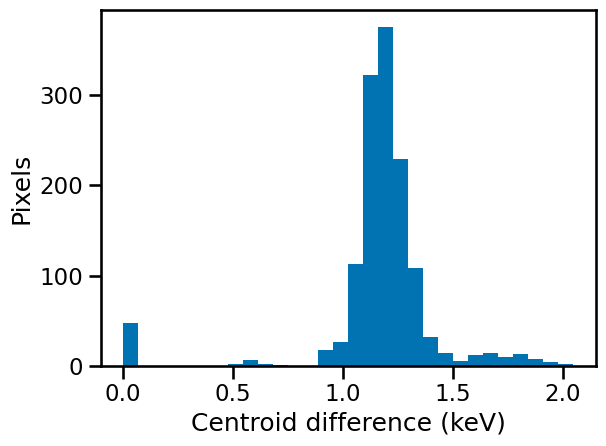

In [ ]:
print(DC_centroid_map, AC_centroid_map)
diff_map_buff = np.ones((39,39)) * -10.
diff_map_buff[1:38,1:38] = DC_centroid_map[1] - AC_centroid_map[1]
diff_map_buff[3:4,:] = -10.0
diff_map_buff[5:6,:] = -10.0
diff_map_buff[11:12,:] = -10.0
diff_map_buff[31:32,:] = -10.0
diff_map_buff[:,11:12] = -10.0
diff_map_buff[:,25:26] = -10.0
diff_map_buff = np.ma.masked_where(~np.isfinite(diff_map_buff) | (diff_map_buff < -1.0), diff_map_buff)
centroid_diff_map = DC_centroid_map[1] - AC_centroid_map[1]
mask = np.ma.getmask(diff_map_buff)
for i in range(37):
    for j in range(37):
        if mask[i+1,j+1]:
            centroid_diff_map[i,j] = np.mean(diff_map_buff[i:i+3, j:j+3])
centroid_diff_map = np.nan_to_num(centroid_diff_map, nan=np.nanmean(centroid_diff_map))
centroid_diff_map_spline_h = RectBivariateSpline(range(37), range(37), centroid_diff_map, s=8)
################## ADDED ##################################################################
# # Zero out or clip positive values in the source map before spline fit
# centroid_diff_map = np.clip(centroid_diff_map, a_min=None, a_max=0)
###########################################################################################

print(diff_map_buff)
# print(centroid_diff_map_spline_h(0,1))

plt.figure()
plt.imshow((DC_centroid_map[1] - AC_centroid_map[1]).T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_map_holes.pdf')
plt.show()

plt.figure()
plt.imshow(diff_map_buff.T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_map_holes.pdf')
plt.show()

plt.figure()
plt.imshow(centroid_diff_map.T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_map_holes.pdf')
plt.show()

plt.figure()
plt.imshow(centroid_diff_map_spline_h(range(37),range(37)).T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_smoothmap_holes.pdf')
plt.show()

plt.figure()
plt.hist(centroid_diff_map.flatten(), bins = 30)
plt.ylabel('Pixels')
plt.xlabel('Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_hist_holes.pdf')

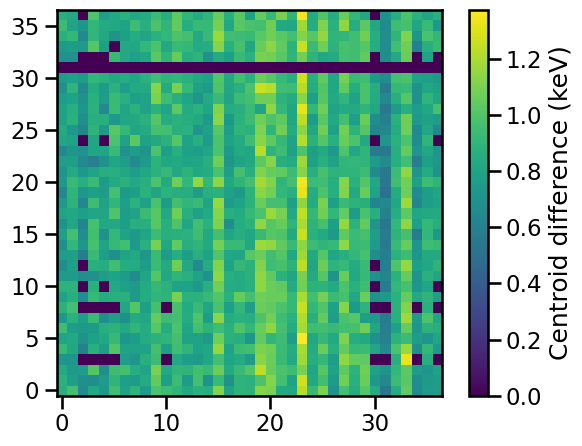

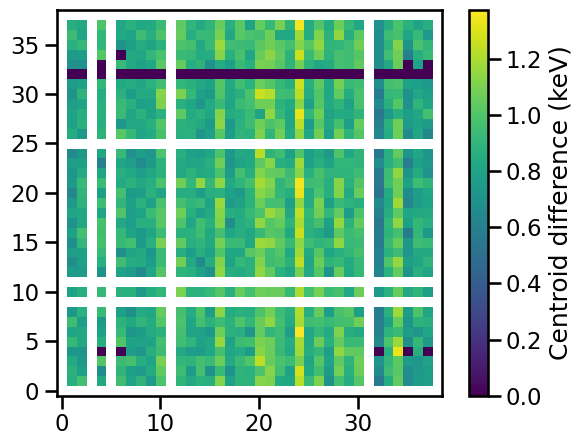

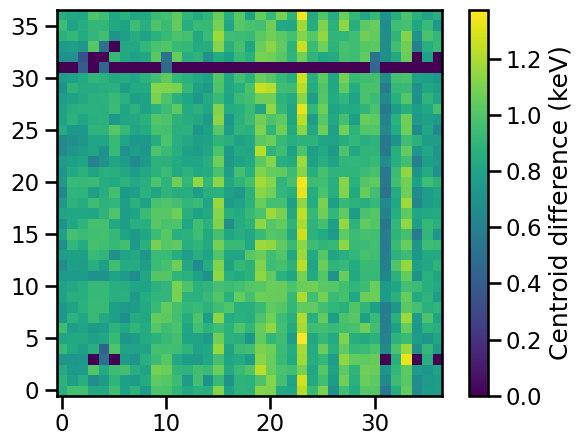

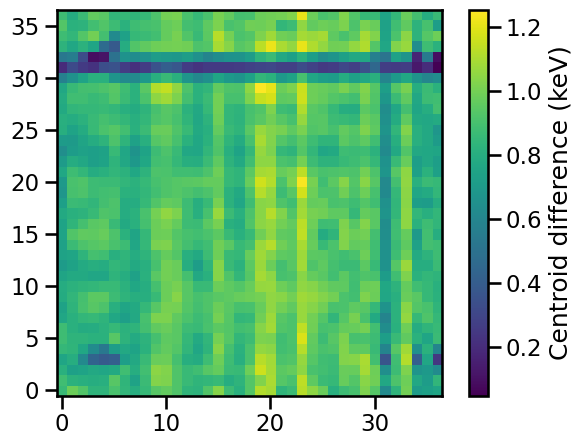

[[0.85949837 0.98491704 0.92586604 ... 0.71443793 0.73132853 0.75728108]
 [0.88276996 0.82058555 0.81000229 ... 0.77068086 0.7163563  0.84102455]
 [0.81123577 0.73114534 0.74781601 ... 0.67003149 0.69551672 0.6314187 ]
 ...
 [0.8793443  0.84669825 0.92933469 ... 0.82768707 0.936052   0.98672564]
 [0.93122533 0.81905323 0.82850033 ... 0.82815427 0.90208175 0.72096202]
 [0.87923183 0.79178706 0.87094383 ... 0.89522592 0.79571306 0.86326459]]


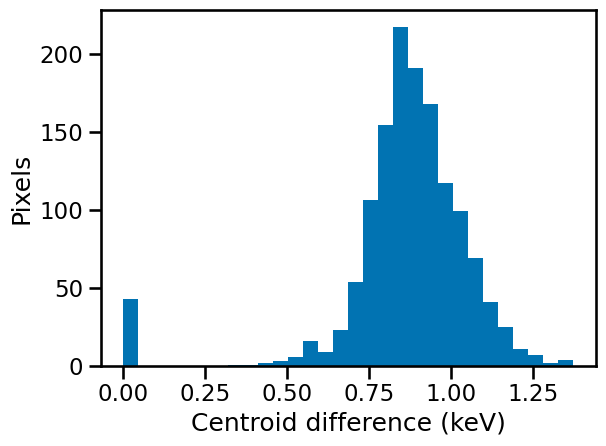

In [131]:
buff = -10. 
diff_map_buff = np.ones((39,39)) * buff
diff_map_buff[1:38,1:38] = DC_centroid_map[0] - AC_centroid_map[0]
diff_map_buff[3:4,:] = buff
diff_map_buff[5:6,:] = buff
diff_map_buff[11:12,:] = buff
diff_map_buff[31:32,:] = buff
diff_map_buff[:,9:10] = buff
diff_map_buff[:,11:12] = buff
diff_map_buff[:,25:26] = buff
diff_map_buff = np.ma.masked_where(~np.isfinite(diff_map_buff) | (diff_map_buff < -1.), diff_map_buff)
# diff_map_buff = np.ma.masked_greater(diff_map_buff, 0.0)
centroid_diff_map = DC_centroid_map[0] - AC_centroid_map[0]
mask = np.ma.getmask(diff_map_buff)
for i in range(37):
    for j in range(37):
        if mask[i+1,j+1]:
            centroid_diff_map[i,j] = np.mean(diff_map_buff[i:i+3, j:j+3])

# ################## ADDED ##################################################################
# # Zero out or clip positive values in the source map before spline fit
# centroid_diff_map = np.clip(centroid_diff_map, a_min=None, a_max=0)
# ###########################################################################################
centroid_diff_map = np.nan_to_num(centroid_diff_map, nan=np.nanmean(centroid_diff_map))
centroid_diff_map_spline_e = RectBivariateSpline(range(37), range(37), centroid_diff_map, s=12)

# print(centroid_diff_map_spline_h(0,1))

plt.figure()
plt.imshow((DC_centroid_map[0] - AC_centroid_map[0]).T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_map_electrons.pdf')
plt.show()

plt.figure()
plt.imshow(diff_map_buff.T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_map_holes.pdf')
plt.show()

plt.figure()
plt.imshow(centroid_diff_map.T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_map_holes.pdf')
plt.show()

plt.figure()
plt.imshow(centroid_diff_map_spline_e(range(37),range(37)).T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_smoothmap_electrons.pdf')
plt.show()

plt.figure()
plt.hist(centroid_diff_map.flatten(), bins = 30)
plt.ylabel('Pixels')
plt.xlabel('Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_hist_holes.pdf')

print(centroid_diff_map_spline_e(range(37),range(37)).T)

Try to mask the positive centroid shifts instead

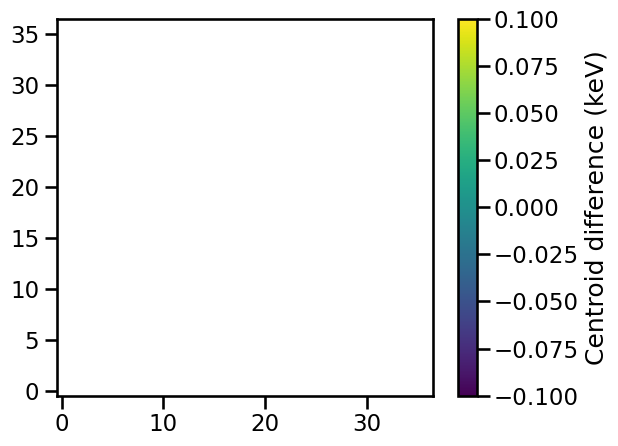

In [132]:
# Evaluate the spline grid
spline_eval_e = centroid_diff_map_spline_e(range(37), range(37))

# Mask values greater than 0
spline_eval_e_masked = np.ma.masked_greater(spline_eval_e, 0)

# Plot the masked spline
plt.figure()
plt.imshow(spline_eval_e_masked.T, origin='lower')

plt.colorbar(label='Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/Am241_ACDC_diff_smoothmap_electrons.pdf')
plt.show()

## Reading in simulations and getting trapping product vs. shift

In [133]:
### where is this from ????

######## ***********************
mfp = 0.09476 # cm
depth_prob = np.exp(-depth_grid/mfp)
n_events = 100000

def depth_cdf(z, mfp):
    return (1./mfp)*(1.-np.exp(-z/mfp))

def inv_cdf(y, mfp, max_depth = 1.51):
    N = (1./mfp)*(1.-np.exp(-max_depth/mfp))
    return mfp*np.log(1.0/(1.0-N*mfp*y))

eprod_grid = np.linspace(0.1, 5.0, num = 25)
hprod_grid = np.linspace(0.1, 5.0, num = 25)
print(min(hprod_grid))

ediff_grid = np.zeros((len(eprod_grid), len(hprod_grid)))
hdiff_grid = np.zeros((len(eprod_grid), len(hprod_grid)))

#populating the h and e energy difference grids (randomly)
for i in range(len(eprod_grid)):
    for j in range(len(hprod_grid)):
        random_depths_DC = inv_cdf(np.random.random(size = n_events), mfp)
        random_depths_AC = inv_cdf(np.random.random(size = n_events), -mfp)
        Eh_z = CubicSpline(depth_grid, Am_line*h_cce(eprod_grid[i], hprod_grid[j]))
        Ee_z = CubicSpline(depth_grid, Am_line*e_cce(eprod_grid[i], hprod_grid[j]))
        random_Eh_AC = Eh_z(random_depths_AC) + np.random.normal(loc=0.0, scale=1., size=n_events)
        random_Eh_DC = Eh_z(random_depths_DC) + np.random.normal(loc=0.0, scale=1., size=n_events)
        random_Ee_AC = Ee_z(random_depths_AC) + np.random.normal(loc=0.0, scale=1., size=n_events)
        random_Ee_DC = Ee_z(random_depths_DC) + np.random.normal(loc=0.0, scale=1., size=n_events)
        ediff_grid[i,j] = np.mean(random_Ee_DC) - np.mean(random_Ee_AC)
        hdiff_grid[i,j] = np.mean(random_Eh_DC) - np.mean(random_Eh_AC)

0.1


0.04720194461311422
-0.175972141072279


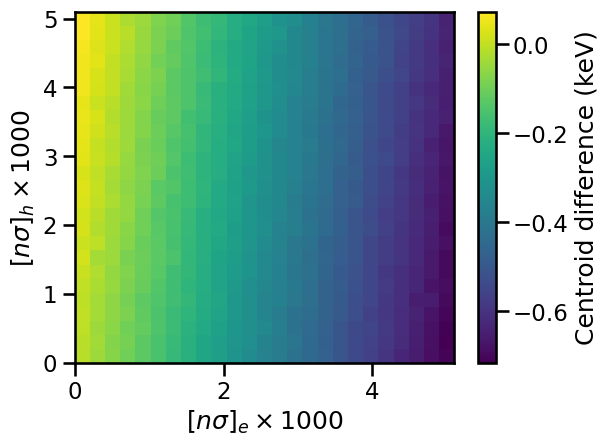

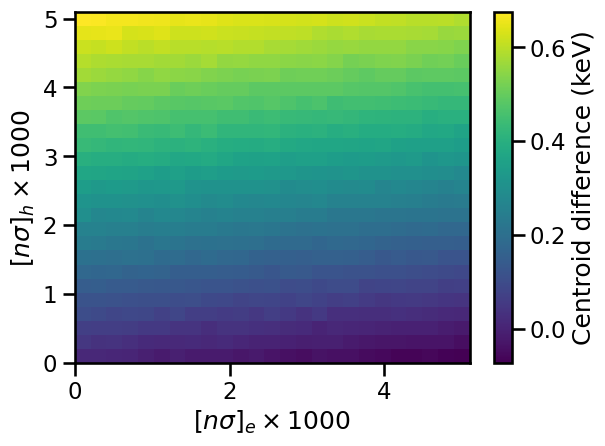

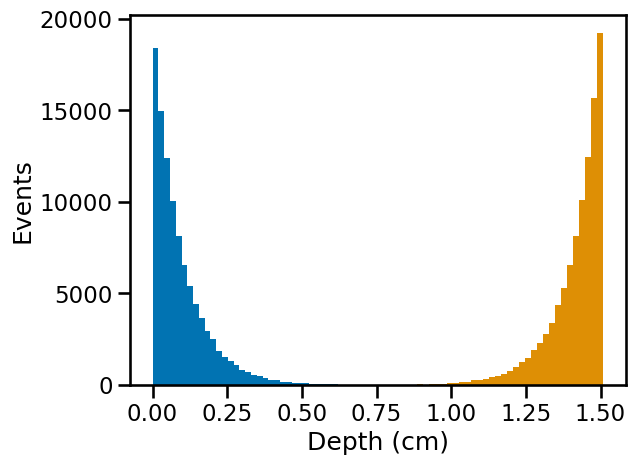

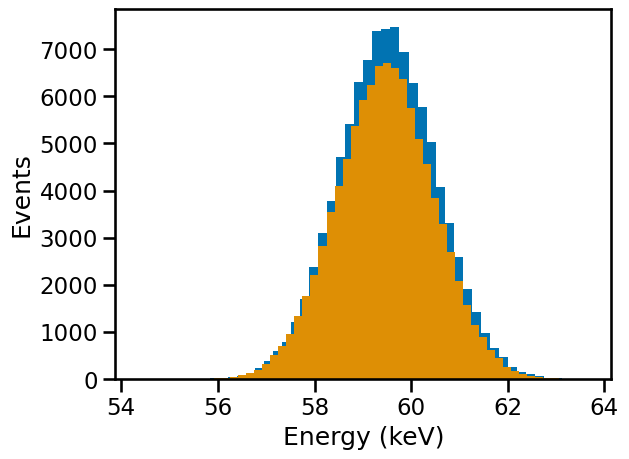

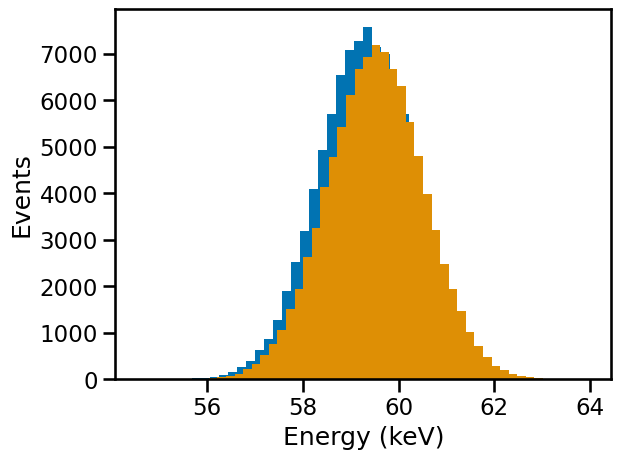

In [134]:
plt.figure()
plt.pcolormesh(*np.meshgrid(eprod_grid, hprod_grid, indexing='ij'), ediff_grid)
plt.xlabel(r'$[n\sigma]_{e} \times 1000$')
plt.ylabel(r'$[n\sigma]_{h} \times 1000$')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/trappingprod_to_ediff_grid.pdf')

plt.figure()
plt.pcolormesh(*np.meshgrid(eprod_grid, hprod_grid, indexing='ij'), hdiff_grid)
plt.xlabel(r'$[n\sigma]_{e} \times 1000$')
plt.ylabel(r'$[n\sigma]_{h} \times 1000$')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/trappingprod_to_hdiff_grid.pdf')

random_depths_AC = inv_cdf(np.random.random(size = n_events), mfp)
random_depths_DC = inv_cdf(np.random.random(size = n_events), -mfp)
Eh_z = CubicSpline(depth_grid, Am_line*h_cce(1.3, 0.540))
random_Eh_AC = Eh_z(random_depths_AC) + np.random.normal(loc=0.0, scale=1., size=n_events)
random_Eh_DC = Eh_z(random_depths_DC) + np.random.normal(loc=0.0, scale=1., size=n_events)

Ee_z = CubicSpline(depth_grid, Am_line*e_cce(1.3, 0.540))
random_Ee_AC = Ee_z(random_depths_AC) + np.random.normal(loc=0.0, scale=1., size=n_events)
random_Ee_DC = Ee_z(random_depths_DC) + np.random.normal(loc=0.0, scale=1., size=n_events)

print(np.mean(random_Eh_AC) - np.mean(random_Eh_DC))
print(np.mean(random_Ee_AC) - np.mean(random_Ee_DC))

plt.figure()
plt.hist(random_depths_AC, bins = 50)
plt.hist(random_depths_DC, bins = 50)
plt.ylabel('Events')
plt.xlabel('Depth (cm)')
plt.show()

plt.figure()
plt.hist(random_Eh_AC, bins = 50)
plt.hist(random_Eh_DC, bins = 50)
plt.ylabel('Events')
plt.xlabel('Energy (keV)')
plt.show()

plt.figure()
plt.hist(random_Ee_AC, bins = 50)
plt.hist(random_Ee_DC, bins = 50)
plt.ylabel('Events')
plt.xlabel('Energy (keV)')
plt.show()


[0.1        0.30416667 0.50833333 0.7125     0.91666667 1.12083333
 1.325      1.52916667 1.73333333 1.9375     2.14166667 2.34583333
 2.55       2.75416667 2.95833333 3.1625     3.36666667 3.57083333
 3.775      3.97916667 4.18333333 4.3875     4.59166667 4.79583333
 5.        ]


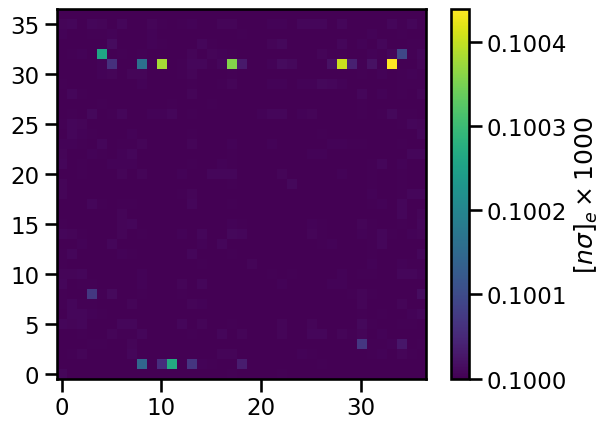

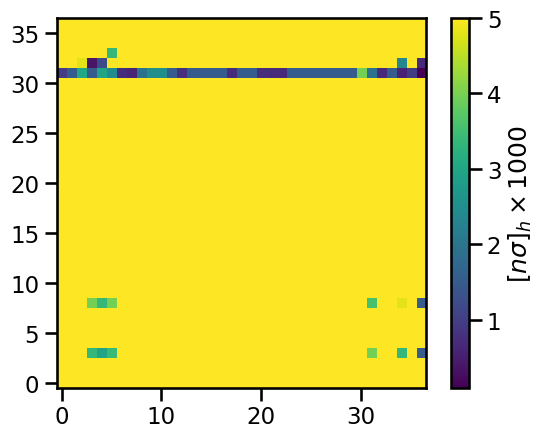

In [135]:
### Next, interpolate both grids, and fit measured differences using the interpolations to get the trapping products.
## its taking the matrix of e prod and h prod and intepolating between each matrix entry to return a continuous grid
hdiff_interp = RegularGridInterpolator((eprod_grid, hprod_grid), hdiff_grid)
ediff_interp = RegularGridInterpolator((eprod_grid, hprod_grid), ediff_grid)

eprod_map = np.zeros(centroid_diff_map.shape)
hprod_map = np.zeros(centroid_diff_map.shape)
print(hprod_grid)
for i in range(37):
    for j in range(37):
        ediff_obs = centroid_diff_map_spline_e(i,j)
        hdiff_obs = centroid_diff_map_spline_h(i,j)
        def distance(eprod, hprod): #cost function is diff between energy diff in data and enrgy diff predetermined??
            return np.square(ediff_obs - ediff_interp((eprod, hprod))) + np.square(hdiff_obs - hdiff_interp((eprod, hprod)))
        m = Minuit(distance, eprod=1.2, hprod=0.8)
        m.limits['eprod']=(np.min(eprod_grid), np.max(eprod_grid))
        m.limits['hprod']=(np.min(hprod_grid), np.max(hprod_grid))
        m.migrad()
        # m.hesse()

        eprod_map[i,j] = m.values['eprod']
        hprod_map[i,j] = m.values['hprod']
    
plt.figure()
plt.imshow(eprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{e} \times 1000$')
plt.savefig(plot_dir + 'preLL/trapping_prod_map_electrons.pdf')

plt.figure()
plt.imshow(hprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{h} \times 1000$')
plt.savefig(plot_dir + 'preLL/trapping_prod_map_holes.pdf')

In [136]:
print(eprod_map.T)
print("Mean [nσe]-1 = ", np.mean(eprod_map)*1000, "Mean [nσh]-1 = ", np.mean(hprod_map)*1000)
print("Standard deviation in [nσe]-1 = ", np.std(eprod_map)*1000, "Standard deviation in [nσh]-1 = ", np.std(hprod_map)*1000)

[[0.10000775 0.10000007 0.10000005 ... 0.1        0.10000001 0.1000011 ]
 [0.1        0.1        0.1        ... 0.1        0.1        0.1       ]
 [0.1        0.10000295 0.10000618 ... 0.10000558 0.1000034  0.1       ]
 ...
 [0.100005   0.10000001 0.1        ... 0.10000226 0.10000001 0.10000105]
 [0.10000594 0.10000805 0.10000001 ... 0.10000269 0.10000742 0.10000211]
 [0.10000002 0.10000012 0.10000017 ... 0.10000001 0.10000014 0.10000002]]
Mean [nσe]-1 =  100.00359080811575 Mean [nσh]-1 =  4878.199681190679
Standard deviation in [nσe]-1 =  0.024764843902972306 Standard deviation in [nσh]-1 =  640.8755988985805


In [103]:
print(eprod_map.T)

[[0.29436205 0.33034466 0.28430493 ... 2.51493214 0.19696602 1.99840314]
 [1.20276097 2.23663384 1.15049043 ... 1.63965921 2.03922084 2.02588511]
 [1.8719576  3.17770124 2.44179723 ... 0.71358306 2.02188123 1.63191659]
 ...
 [2.17349422 2.05026469 2.82696255 ... 3.2744572  0.99228054 1.8900974 ]
 [0.94262354 3.84288266 1.95716774 ... 2.09061988 1.55834615 2.3589252 ]
 [1.35132295 4.4364259  4.42656613 ... 0.81961254 2.73248043 1.92588141]]


In [104]:
from scipy.stats import gmean, gstd  # Alternatively using scipy



# Filter out non-positive values to prevent log errors
eprod_valid = eprod_map[eprod_map > 0]
hprod_valid = hprod_map[hprod_map > 0]

# Calculate Geometric Mean (scaled by 1000 to match your units)
geom_mean_e = np.exp(np.mean(np.log(eprod_valid))) * 1000
geom_mean_h = np.exp(np.mean(np.log(hprod_valid))) * 1000

# Calculate Geometric Standard Deviation (multiplicative factor)
geom_std_e = np.exp(np.std(np.log(eprod_valid)))
geom_std_h = np.exp(np.std(np.log(hprod_valid)))

print(f"Geometric Mean [nσe]-1 = {geom_mean_e:.7f}  (GSTD factor = {geom_std_e:.3f})")
print(f"Geometric Mean [nσh]-1 = {geom_mean_h:.7f}  (GSTD factor = {geom_std_h:.3f})")

Geometric Mean [nσe]-1 = 1466.4058035  (GSTD factor = 2.038)
Geometric Mean [nσh]-1 = 2610.3498923  (GSTD factor = 1.395)


2.551263995587751


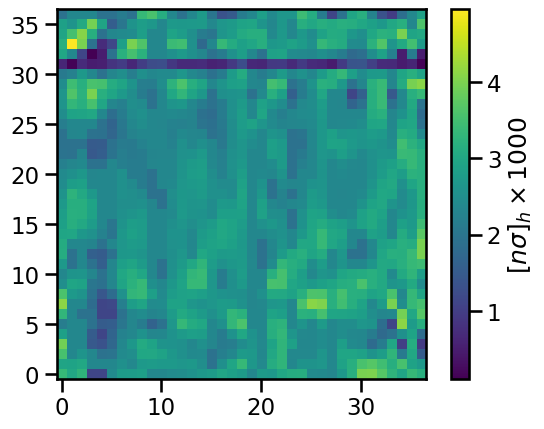

In [105]:
#fix e trapping in the fitted product map
eprod_map = np.zeros(centroid_diff_map.shape)
hprod_map = np.zeros(centroid_diff_map.shape)

for i in range(37):
    for j in range(37):
        ediff_obs = centroid_diff_map_spline_e(i,j)
        hdiff_obs = centroid_diff_map_spline_h(i,j)
        def distance(eprod, hprod):
            return np.square(ediff_obs - ediff_interp((eprod, hprod))) + np.square(hdiff_obs - hdiff_interp((eprod, hprod)))
        m = Minuit(distance, eprod=1.2, hprod=0.7)
        m.fixed['eprod'] = True
        m.limits['hprod']=(np.min(hprod_grid), np.max(hprod_grid))
        # print(np.min(hprod_grid))
        m.migrad()
        # m.hesse()

        hprod_map[i,j] = m.values['hprod']
 
plt.figure()
plt.imshow(hprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{h} \times 1000$')
plt.savefig(plot_dir + 'preLL/trapping_prod_map_holes_etrapfixed.pdf')
print(hprod_map.mean())

0.1
1.4346419134088229


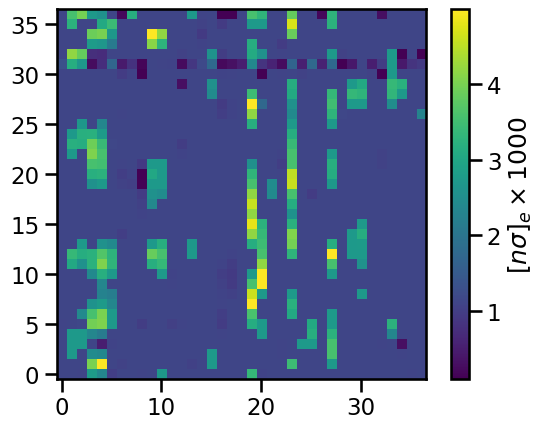

In [106]:
#fix h trapping 
eprod_map = np.zeros(centroid_diff_map.shape)
hprod_map = np.zeros(centroid_diff_map.shape)

for i in range(37):
    for j in range(37):
        ediff_obs = centroid_diff_map_spline_e(i,j)
        hdiff_obs = centroid_diff_map_spline_h(i,j)
        def distance(eprod, hprod):
            return np.square(ediff_obs - ediff_interp((eprod, hprod))) + np.square(hdiff_obs - hdiff_interp((eprod, hprod)))
        m = Minuit(distance, eprod=1.0, hprod=0.7)
        m.limits['eprod']=(np.min(eprod_grid), np.max(eprod_grid))
        m.fixed['hprod'] = True
        m.migrad()
        # m.hesse()

        eprod_map[i,j] = m.values['eprod']
        hprod_map[i,j] = m.values['hprod']
print(np.min(hprod_grid) )  
plt.figure()
plt.imshow(eprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{e} \times 1000$')
plt.savefig(plot_dir + 'trapping_prod_map_electrons_htrapfixed.pdf')

eprod_map_preLL = eprod_map
print(eprod_map.mean())



# Post LL1

In [107]:
files = [["20262201_Am241_AC_1200V_80K.dat"], \
                      ["20262201_Am241_DC_1200V_80K.dat" ]]


erange = [50., 64.]

emin = erange[0]
emax = erange[1]
bins = int((emax-emin) * 4)

AC_centroid_map = np.zeros((2, 37, 37))
DC_centroid_map = np.zeros_like(AC_centroid_map)

fullpaths = []
for p in files[0]:
    fullpaths.append(datpath  + p)

df_AC = make_df_from_dat(fullpaths, e_min=emin, e_max=emax)

fullpaths = []
for p in files[1]:
    fullpaths.append(datpath + p)

df_DC = make_df_from_dat(fullpaths, e_min=emin, e_max=emax)

print(df_AC.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2503005 entries, 0 to 2503004
Data columns (total 13 columns):
 #   Column    Dtype  
---  ------    -----  
 0   ID        int64  
 1   det       int64  
 2   strip_p   int64  
 3   energy_p  float64
 4   time_p    float64
 5   strip_n   int64  
 6   energy_n  float64
 7   time_n    float64
 8   x         float64
 9   y         float64
 10  z         float64
 11  z_err     float64
 12  bad       bool   
dtypes: bool(1), float64(8), int64(4)
memory usage: 231.5 MB
None


In [ ]:
AC_centroid_map = np.full((2, 37, 37), np.nan)
DC_centroid_map = np.full((2, 37, 37), np.nan)
n_failed = {'AC': 0, 'DC': 0}
pixel_counter = 0

for p in range(37):
    for n in range(37):
            # Determine if this pixel should generate fit plots
            should_plot = (pixel_counter % 500 == 0)

            AC_sliced = df_AC.loc[(df_AC['strip_p']==p+1) & (df_AC['strip_n']==n+1)]
            DC_sliced = df_DC.loc[(df_DC['strip_p']==p+1) & (df_DC['strip_n']==n+1)]
            if (len(AC_sliced) > 1000) & (len(DC_sliced) > 1000):

                for i, side in enumerate(['p','n']):
                    gain_factor = gain_factor_map[i][p if side == 'p' else n]

                    x0, m = fit_am241_centroid(AC_sliced['energy_' + side].values, emin, emax)
                    AC_centroid_map[i][p][n] = x0*gain_factor
                    n_failed['AC'] += np.isnan(x0)

                    energies = DC_sliced['energy_' + side].values
                    x0, m = fit_am241_centroid(energies, emin, emax)
                    DC_centroid_map[i][p][n] = x0*gain_factor
                    n_failed['DC'] += np.isnan(x0)

                    if should_plot and m is not None:
                        plot_photopeak_fit_with_components(
                            energies=energies[(energies > emin) & (energies < emax)],
                            minuit_fit=m,
                            pdf_func=gauss_minus_linear_tail_pdf,
                            component_pdfs={
                                'Gaussian Peak': gaussian_component,
                                'Low-Energy Tail': tail_component
                            },
                            n_bins=80,
                            title=f"DC Fit - Side {side} (p={p}, n={n})"
                        )
                pixel_counter += 1

# Sanity checks: a stuck fit used to leave x0 at the 60 keV starting value everywhere
print('Failed fits:', n_failed)
for name, cmap in [('AC', AC_centroid_map), ('DC', DC_centroid_map)]:
    for i, side in enumerate(['p', 'n']):
        print(name, side, 'centroid mean = %.3f, std = %.3f keV' % (np.nanmean(cmap[i]), np.nanstd(cmap[i])))


/Users/Sophie/Desktop/COSI/calibrations/Data/depth_helpers.py:58: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  quad(gauss_plus_tail, Emin, Emax, args=(BoverA, x0, sigma_gauss, gamma, CoverB, D, sigma_ratio))[0]


NaNs: 3
Infs: 0
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


/var/folders/g9/70rty0x929vfgjpdhdclnn7m0000gq/T/ipykernel_510/623536617.py:19: UserWarning: Warning: converting a masked element to nan.
  centroid_diff_map[i,j] = np.mean(diff_map_buff[i:i+2, j:j+2])


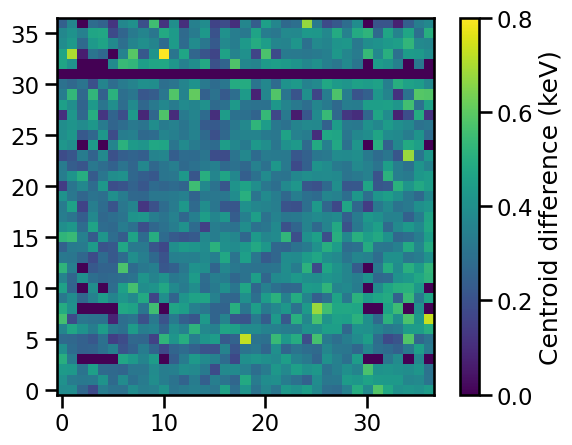

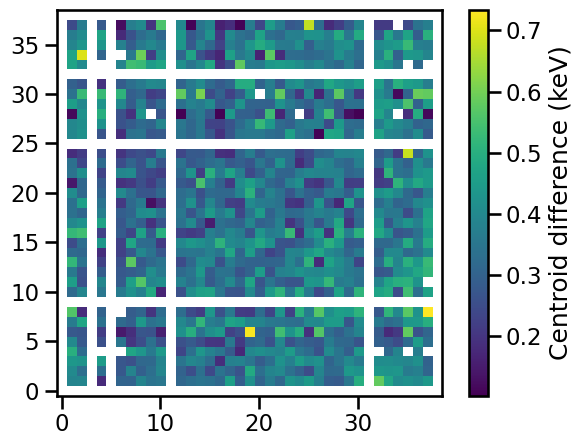

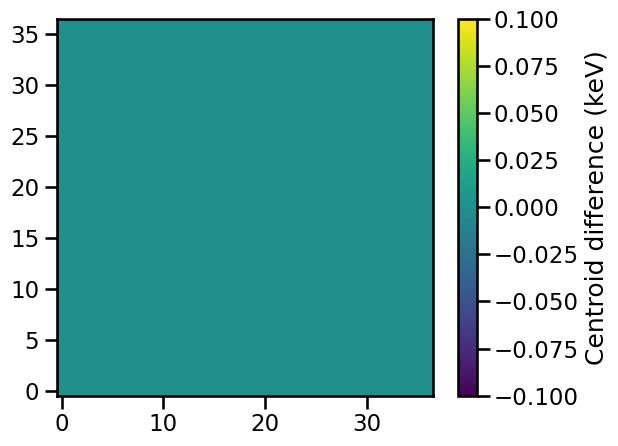

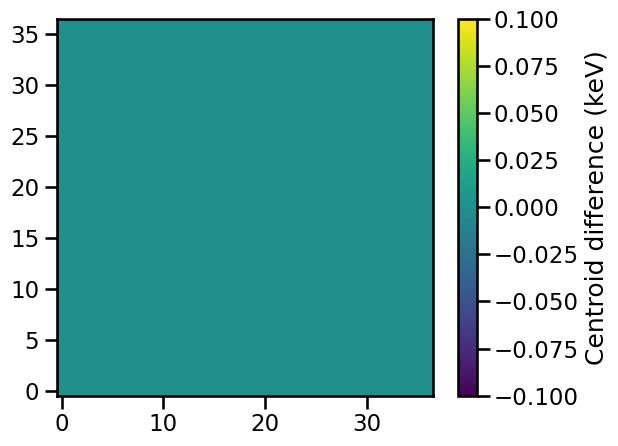

0.0


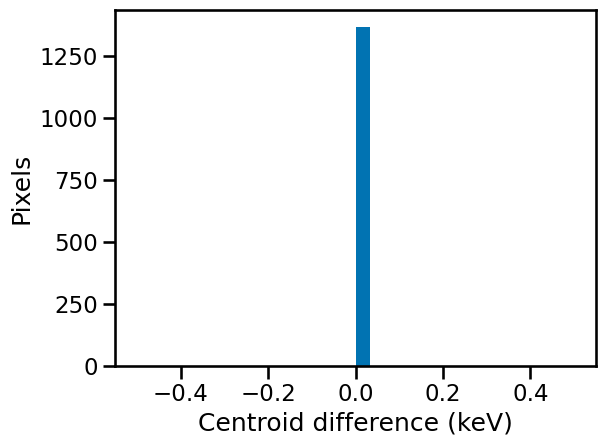

In [109]:
diff_map_buff = np.zeros((39,39))
diff_map_buff[1:38,1:38] = DC_centroid_map[1] - AC_centroid_map[1]
diff_map_buff[3:4,:] = 0.0
diff_map_buff[5:6,:] = 0.0
diff_map_buff[11:12,:] = 0.0
diff_map_buff[31:32,:] = 0.0
diff_map_buff[:,9:10] = 0.0
diff_map_buff[:,25:26] = 0.0
diff_map_buff = np.ma.masked_where(~np.isfinite(diff_map_buff) | (diff_map_buff < 0.1) | (diff_map_buff > 2.3), diff_map_buff)
# print(diff_map_buff)

centroid_diff_map = DC_centroid_map[1] - AC_centroid_map[1]
# print(centroid_diff_map)
mask = np.ma.getmask(diff_map_buff)
# print(mask)
for i in range(37):
    for j in range(37):
        if mask[i+1,j+1]:
            centroid_diff_map[i,j] = np.mean(diff_map_buff[i:i+3, j:j+3])

            
centroid_diff_map = np.array(centroid_diff_map, dtype=float)

## dealing with NaN in the data which after smoothing result in a map full of NaNs
print("NaNs:", np.isnan(centroid_diff_map).sum())
print("Infs:", np.isinf(centroid_diff_map).sum())
# Replace any remaining bad values
centroid_diff_map = np.nan_to_num(centroid_diff_map, nan=np.nanmean(centroid_diff_map))

centroid_diff_map_spline_h = RectBivariateSpline(range(37), range(37), centroid_diff_map, s=8)

x = np.arange(37)
y = np.arange(37)

z_smooth = centroid_diff_map_spline_h(x, y)



print(z_smooth)

plt.figure()
plt.imshow((DC_centroid_map[1] - AC_centroid_map[1]).T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
#plt.savefig(plot_dir + 'postLL1/Am241_ACDC_diff_map_holes.pdf')
plt.show()

plt.figure()
plt.imshow(diff_map_buff.T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
#plt.savefig(plot_dir + 'postLL1/Am241_ACDC_diff_map_holes_masked.pdf')
plt.show()

plt.figure()
plt.imshow(centroid_diff_map.T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
#plt.savefig(plot_dir + 'postLL1/Am241_ACDC_diff_map_holes_interp.pdf')
plt.show()

plt.figure()
plt.imshow(centroid_diff_map_spline_h(range(37),range(37)).T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
#plt.savefig(plot_dir + 'postLL1/Am241_ACDC_diff_smoothmap_holes.pdf')
plt.show()

plt.figure()
plt.hist(centroid_diff_map.flatten(), bins = 30)
plt.ylabel('Pixels')
plt.xlabel('Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/Am241_ACDC_diff_hist_holes.pdf')

print(centroid_diff_map.T.mean())

[[ 0.00412154 -0.12294616 -0.21266668 ... -0.25346374 -0.08744477
  -0.15908212]
 [ 0.0103415  -0.26261082 -0.39839035 ... -0.23748784 -0.4520566
  -0.59446521]
 [-0.00268205 -0.13767662 -0.29885366 ... -0.31467918 -0.2367162
  -0.5707477 ]
 ...
 [-0.28758398 -0.18046317 -0.08090028 ... -0.36322351 -0.25920487
  -0.09818578]
 [ 0.01099529 -0.24154209 -0.23139476 ... -0.09924253 -0.1830506
  -0.3379669 ]
 [-0.22924755 -0.24269848 -0.20570983 ... -0.19148792 -0.28454464
  -0.22748277]]


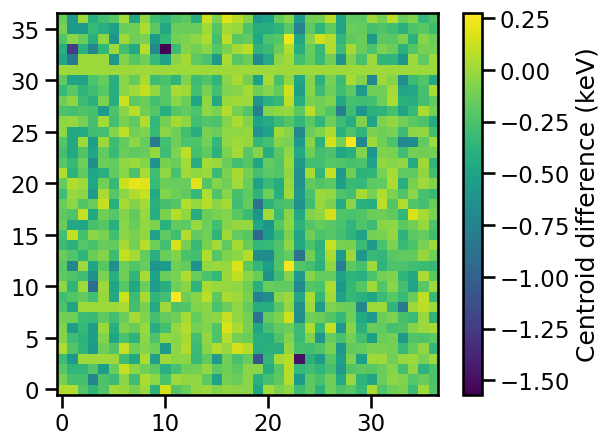

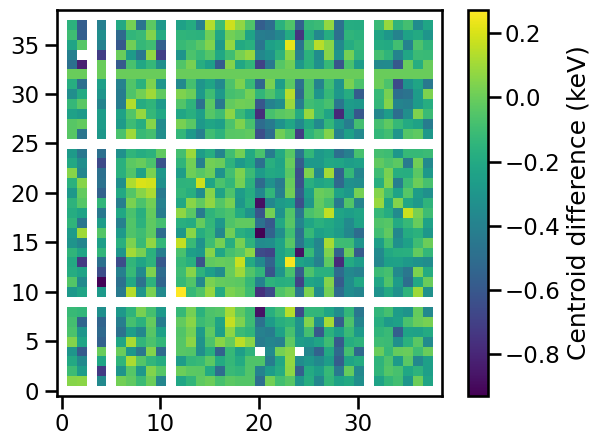

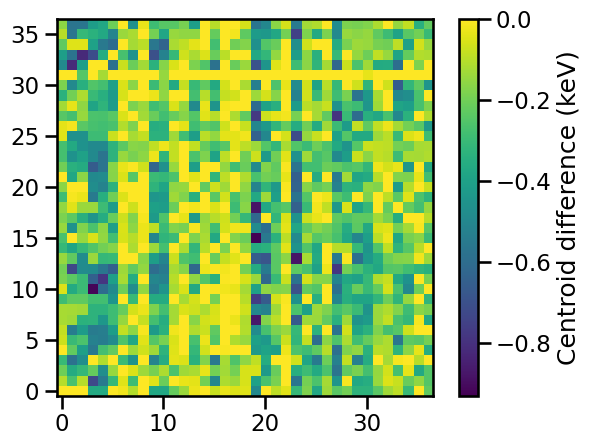

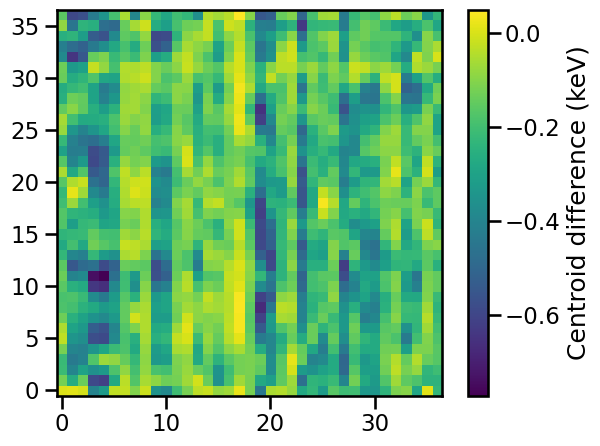

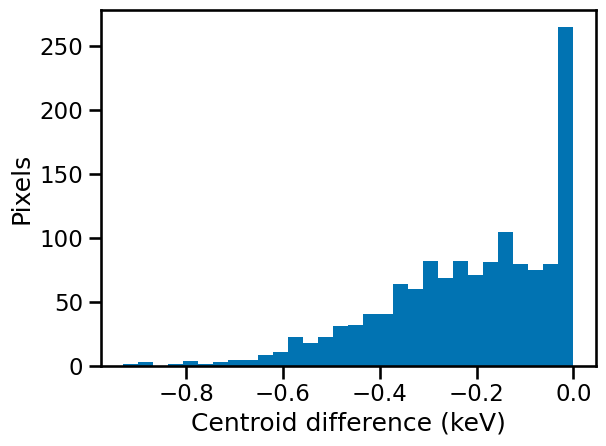

In [110]:
diff_map_buff = np.ones((39,39)) * -10.
diff_map_buff[1:38,1:38] = DC_centroid_map[0] - AC_centroid_map[0]
diff_map_buff[3:4,:] = -10.0
diff_map_buff[5:6,:] = -10.0
diff_map_buff[11:12,:] = -10.0
diff_map_buff[31:32,:] = -10.0
diff_map_buff[:,9:10] = -10.0
diff_map_buff[:,25:26] = -10.0
diff_map_buff = np.ma.masked_where(~np.isfinite(diff_map_buff) | (diff_map_buff < -1.), diff_map_buff)

centroid_diff_map = DC_centroid_map[0] - AC_centroid_map[0]

mask = np.ma.getmask(diff_map_buff)
for i in range(37):
    for j in range(37):
        if mask[i+1,j+1]:
            centroid_diff_map[i,j] = np.mean(diff_map_buff[i:i+3, j:j+3])

centroid_diff_map = np.nan_to_num(centroid_diff_map, nan=np.nanmean(centroid_diff_map))
centroid_diff_map_spline_e = RectBivariateSpline(range(37), range(37), centroid_diff_map, s=12)
x = np.arange(37)
y = np.arange(37)

z_smooth = centroid_diff_map_spline_e(x, y)

print(z_smooth)
# print(centroid_diff_map_spline_h(0,1))

plt.figure()
plt.imshow((DC_centroid_map[0] - AC_centroid_map[0]).T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/Am241_ACDC_diff_map_electrons.pdf')
plt.show()

plt.figure()
plt.imshow(diff_map_buff.T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/Am241_ACDC_diff_map_holes_mask.pdf')
plt.show()

plt.figure()
plt.imshow(centroid_diff_map.T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/Am241_ACDC_diff_map_holes_interp.pdf')
plt.show()

plt.figure()
plt.imshow(centroid_diff_map_spline_e(range(37),range(37)).T, origin='lower')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/Am241_ACDC_diff_smoothmap_electrons.pdf')
plt.show()

plt.figure()
plt.hist(centroid_diff_map.flatten(), bins = 30)
plt.ylabel('Pixels')
plt.xlabel('Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/Am241_ACDC_diff_hist_holes.pdf')

## Reading in simulations and getting trapping product vs. shift

In [111]:
mfp = 0.09476 # cm
depth_prob = np.exp(-depth_grid/mfp)
n_events = 100000

def depth_cdf(z, mfp):
    return (1./mfp)*(1.-np.exp(-z/mfp))

def inv_cdf(y, mfp, max_depth = 1.51):
    N = (1./mfp)*(1.-np.exp(-max_depth/mfp))
    return mfp*np.log(1.0/(1.0-N*mfp*y))

eprod_grid = np.linspace(0.1, 5.0, num = 25)
hprod_grid = np.linspace(0.1, 5.0, num = 25)

ediff_grid = np.zeros((len(eprod_grid), len(hprod_grid)))
hdiff_grid = np.zeros((len(eprod_grid), len(hprod_grid)))

for i in range(len(eprod_grid)):
    for j in range(len(hprod_grid)):
        random_depths_DC = inv_cdf(np.random.random(size = n_events), mfp)
        random_depths_AC = inv_cdf(np.random.random(size = n_events), -mfp)
        Eh_z = CubicSpline(depth_grid, Am_line*h_cce(eprod_grid[i], hprod_grid[j]))
        Ee_z = CubicSpline(depth_grid, Am_line*e_cce(eprod_grid[i], hprod_grid[j]))
        random_Eh_AC = Eh_z(random_depths_AC) + np.random.normal(loc=0.0, scale=1., size=n_events)
        random_Eh_DC = Eh_z(random_depths_DC) + np.random.normal(loc=0.0, scale=1., size=n_events)
        random_Ee_AC = Ee_z(random_depths_AC) + np.random.normal(loc=0.0, scale=1., size=n_events)
        random_Ee_DC = Ee_z(random_depths_DC) + np.random.normal(loc=0.0, scale=1., size=n_events)
        ediff_grid[i,j] = np.mean(random_Ee_DC) - np.mean(random_Ee_AC)
        hdiff_grid[i,j] = np.mean(random_Eh_DC) - np.mean(random_Eh_AC)

1.2684219088242727
-0.021103342384556356


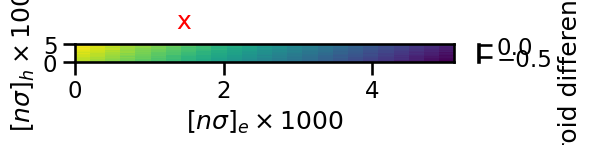

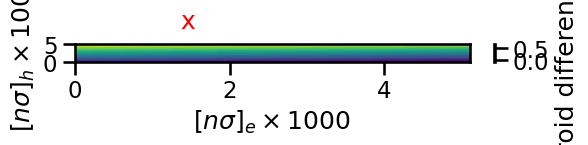

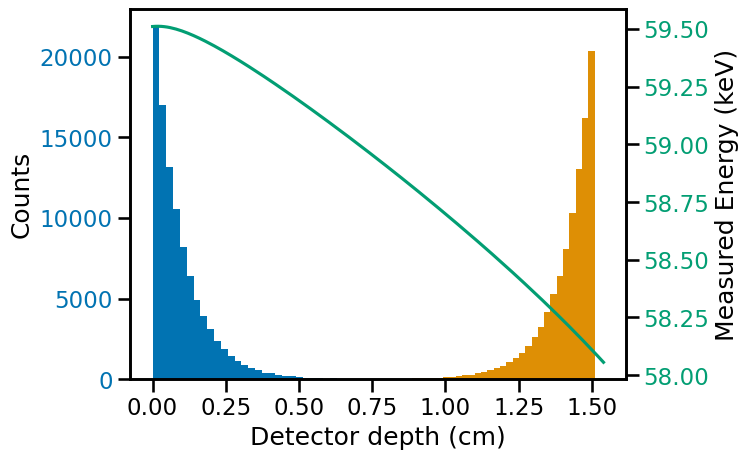

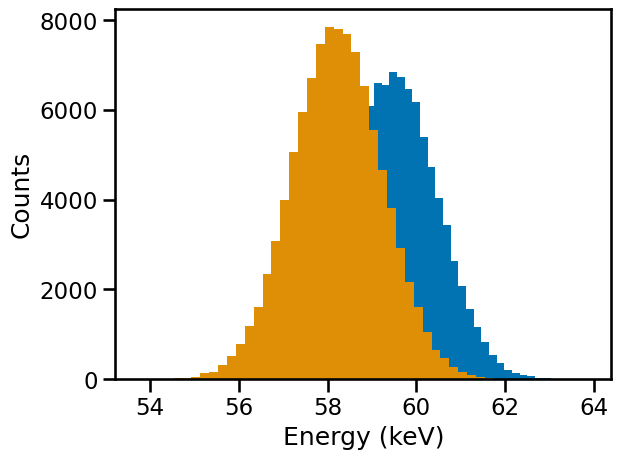

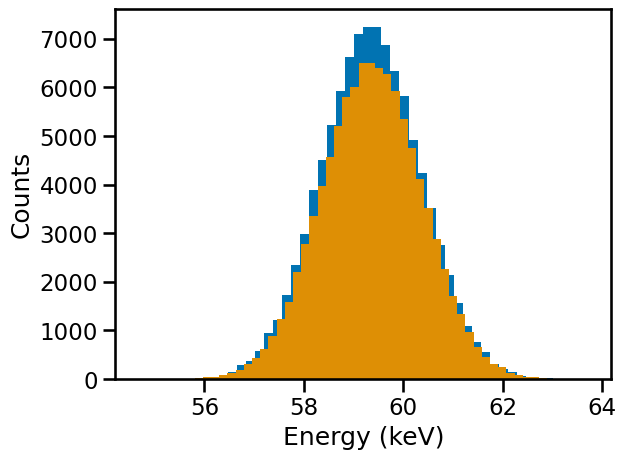

In [112]:
plt.figure()
plt.pcolormesh(*np.meshgrid(eprod_grid, hprod_grid, indexing='ij'), ediff_grid)
plt.xlabel(r'$[n\sigma]_{e} \times 1000$')
plt.ylabel(r'$[n\sigma]_{h} \times 1000$')
plt.text(1.367, 9.463, 'x', color='red')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/trappingprod_to_ediff_grid.pdf')

plt.figure()
plt.pcolormesh(*np.meshgrid(eprod_grid, hprod_grid, indexing='ij'), hdiff_grid)
plt.xlabel(r'$[n\sigma]_{e} \times 1000$')
plt.ylabel(r'$[n\sigma]_{h} \times 1000$')
plt.text(1.367, 9.463, 'x', color='red')
plt.colorbar(label = 'Centroid difference (keV)')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/trappingprod_to_hdiff_grid.pdf')

random_depths_AC = inv_cdf(np.random.random(size = n_events), mfp)
random_depths_DC = inv_cdf(np.random.random(size = n_events), -mfp)
Eh_z = CubicSpline(depth_grid, Am_line*h_cce(1.3, 9.5))
random_Eh_AC = Eh_z(random_depths_AC) + np.random.normal(loc=0.0, scale=1., size=n_events)
random_Eh_DC = Eh_z(random_depths_DC) + np.random.normal(loc=0.0, scale=1., size=n_events)

Ee_z = CubicSpline(depth_grid, Am_line*e_cce(1.3, 9.5))
random_Ee_AC = Ee_z(random_depths_AC) + np.random.normal(loc=0.0, scale=1., size=n_events)
random_Ee_DC = Ee_z(random_depths_DC) + np.random.normal(loc=0.0, scale=1., size=n_events)

print(np.mean(random_Eh_AC) - np.mean(random_Eh_DC))
print(np.mean(random_Ee_AC) - np.mean(random_Ee_DC))

fig, ax1 = plt.subplots()
ax1.hist(random_depths_AC, bins = 50, color='C0')
ax1.hist(random_depths_DC, bins = 50, color='C1')
ax1.set_xlabel('Detector depth (cm)')
ax1.set_ylabel('Counts')
ax1.tick_params(axis='y', labelcolor='C0')
ax2 = ax1.twinx()
ax2.plot(depth_grid, Eh_z(depth_grid), color='C2')
# ax2.plot(depth_grid, Ee_z(depth_grid), color='C2', ls='dotted')
ax2.set_ylabel('Measured Energy (keV)')
ax2.tick_params(axis='y', labelcolor='C2')
plt.show()

plt.figure()
plt.hist(random_Eh_AC, bins = 50, color='C0')
plt.hist(random_Eh_DC, bins = 50, color='C1')
plt.xlabel('Energy (keV)')
plt.ylabel('Counts')
plt.show()

plt.figure()
plt.hist(random_Ee_AC, bins = 50)
plt.hist(random_Ee_DC, bins = 50)
plt.xlabel('Energy (keV)')
plt.ylabel('Counts')
plt.show()


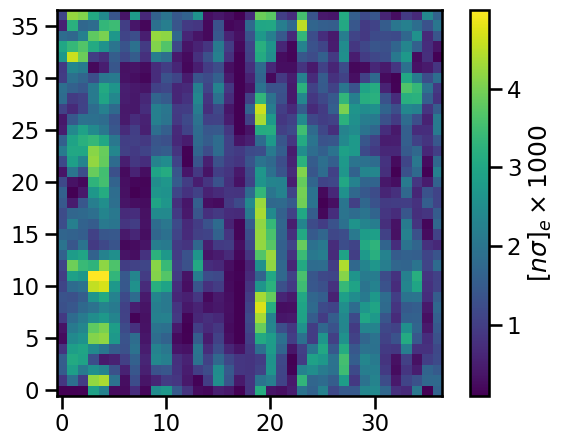

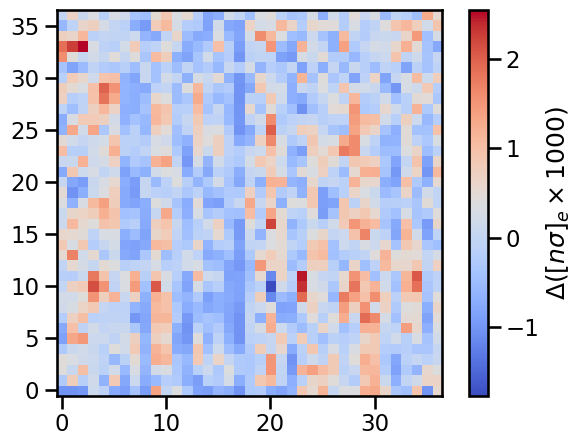

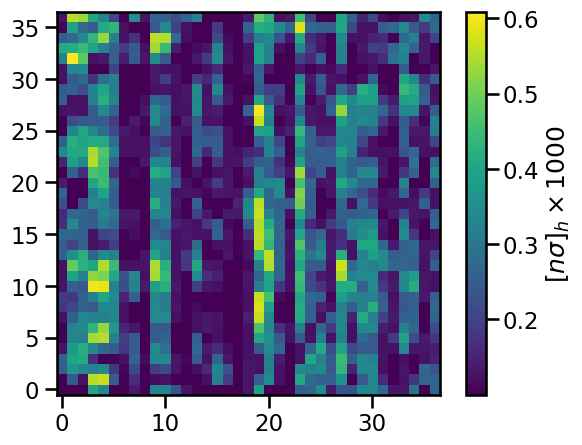

In [113]:
### Next, interpolate both grids, and fit measured differences using the interpolations to get the trapping products.
hdiff_interp = RegularGridInterpolator((eprod_grid, hprod_grid), hdiff_grid)
ediff_interp = RegularGridInterpolator((eprod_grid, hprod_grid), ediff_grid)

eprod_map = np.zeros(centroid_diff_map.shape)
hprod_map = np.zeros(centroid_diff_map.shape)


for i in range(37):
    for j in range(37):
        ediff_obs = centroid_diff_map_spline_e(i,j)
        # print(ediff_obs)
        hdiff_obs = centroid_diff_map_spline_h(i,j)
        def distance(eprod, hprod):
            return np.square(ediff_obs - ediff_interp((eprod, hprod))) + np.square(hdiff_obs - hdiff_interp((eprod, hprod)))
        m = Minuit(distance, eprod=1.0, hprod=0.5)
        m.limits['eprod']=(np.min(eprod_grid), np.max(eprod_grid))
        m.limits['hprod']=(np.min(hprod_grid), np.max(hprod_grid))
        m.migrad()
        # m.hesse()

        eprod_map[i,j] = m.values['eprod']
        hprod_map[i,j] = m.values['hprod']
    
plt.figure()
plt.imshow(eprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{e} \times 1000$')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/trapping_prod_map_electrons.pdf')

plt.figure()
plt.imshow((eprod_map - eprod_map_preLL).T, origin='lower', cmap='coolwarm')
plt.colorbar(label=r'$\Delta([n\sigma]_{e} \times 1000)$')
plt.tight_layout()
plt.savefig(plot_dir + 'preLL/trapping_prod_map_electrons_change.pdf')

plt.figure()
plt.imshow(hprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{h} \times 1000$')
plt.tight_layout()
plt.savefig(plot_dir + 'postLL/trapping_prod_map_holes.pdf')

In [ ]:
### Diagnostics: is the measured post-LL shift something the simulation grid can reproduce, and how precisely?
# NB: the grid uses diff = DC - AC with DC events at depth ~0 (inv_cdf(+mfp)).
#     The sanity-check cell above swaps the AC/DC labels, so its printed values have the opposite sign.

print('Simulated hole-side shift  (DC-AC): %.3f to %.3f keV' % (hdiff_grid.min(), hdiff_grid.max()))
print('Simulated elec-side shift  (DC-AC): %.3f to %.3f keV' % (ediff_grid.min(), ediff_grid.max()))
print('Hole shift at (eprod, hprod) = (1, 0.1) -> (1, 5): %.3f -> %.3f keV' % (
    hdiff_interp((1.0, 0.1)), hdiff_interp((1.0, 5.0))))

# Sensitivity: keV of shift per unit of trapping product (grid units, i.e. x1000 in the printed means)
dE_de = np.gradient(ediff_grid, eprod_grid, axis=0)
dH_dh = np.gradient(hdiff_grid, hprod_grid, axis=1)
print('d(ediff)/d(eprod): median %.3f keV/unit' % np.median(dE_de))
print('d(hdiff)/d(hprod): median %.3f keV/unit' % np.median(dH_dh))

# Pixel-to-pixel noise in the measured shifts: raw map minus its smoothed spline
x = np.arange(37)
for name, side, spline, sens in [('electron', 0, centroid_diff_map_spline_e, dE_de),
                                 ('hole', 1, centroid_diff_map_spline_h, dH_dh)]:
    raw = DC_centroid_map[side] - AC_centroid_map[side]
    smooth = spline(x, x)
    noise = np.nanstd(raw - smooth)
    lo = (ediff_grid if side == 0 else hdiff_grid).min()
    hi = (ediff_grid if side == 0 else hdiff_grid).max()
    outside = np.sum((smooth < lo) | (smooth > hi))
    print('%s side: raw shift %.3f +- %.3f keV, pixel noise %.3f keV -> product noise ~%.2f units; '
          '%d / %d smoothed pixels outside the simulated range'
          % (name, np.nanmean(raw), np.nanstd(raw), noise, noise / np.abs(np.median(sens)), outside, smooth.size))

    plt.figure()
    plt.hist(raw[np.isfinite(raw)].ravel(), bins=40, histtype='step', label='raw')
    plt.hist(smooth.ravel(), bins=40, histtype='step', label='smoothed')
    plt.axvspan(lo, hi, color='gray', alpha=0.2, label='reachable by sims')
    plt.xlabel('%s-side centroid shift DC-AC (keV)' % name)
    plt.ylabel('Pixels')
    plt.legend()
    plt.tight_layout()
    plt.show()

print('Pixels with eprod at grid bounds:', np.sum(np.isclose(eprod_map, eprod_grid.min()) | np.isclose(eprod_map, eprod_grid.max())))
print('Pixels with hprod at grid bounds:', np.sum(np.isclose(hprod_map, hprod_grid.min()) | np.isclose(hprod_map, hprod_grid.max())))

In [114]:
print("Mean [nσe]-1 = ", np.mean(eprod_map)*1000, "Mean change from pre-LL [nσe]-1 = ", np.mean(eprod_map - eprod_map_preLL)*1000, "Mean [nσh]-1 = ", np.mean(hprod_map)*1000)
print("Standard deviation in [nσe]-1 = ", np.std(eprod_map)*1000, "Standard deviation in [nσh]-1 = ", np.std(hprod_map)*1000)

Mean [nσe]-1 =  103.4982177327526 Mean [nσh]-1 =  221.57995210563516
Standard deviation in [nσe]-1 =  1004.7904045462664 Standard deviation in [nσh]-1 =  118.30456848770864


p 0 n 0 1.1204939647678127 0.4117960418068328

p 0 n 1 1.1204692791130866 0.1326584332318886

p 0 n 2 1.120834680161618 0.10469834158393244

p 0 n 3 1.1208334930759674 0.10455089456523416

p 0 n 4 1.1208214936384389 0.13948406229443952

p 0 n 5 1.1062101714216612 0.3328464370816264

p 0 n 6 1.1206579617600745 0.18187000187039118

p 0 n 7 1.1208293168487213 0.10099965549303465

p 0 n 8 1.120835086427752 0.11643960981874413

p 0 n 9 1.1209242510962587 0.12392221525220419

p 0 n 10 1.1214808206261897 0.11075553296881867

p 0 n 11 1.1208343356946442 0.1246074220735493

p 0 n 12 1.120864835660826 0.10181828927130124

p 0 n 13 1.12092282212183 0.10108283557018682

p 0 n 14 1.1208333341476342 0.10219123251828686

p 0 n 15 1.120830929248985 0.10091331573003277

p 0 n 16 1.120938888083437 0.11049502590407145

p 0 n 17 1.1208334351445521 0.10723831896118269

p 0 n 18 1.1211896061183109 0.1000833161076018

p 0 n 19 1.120833619415523 0.10124171344485319

p 0 n 20 1.120833272217565 0.10664823098143

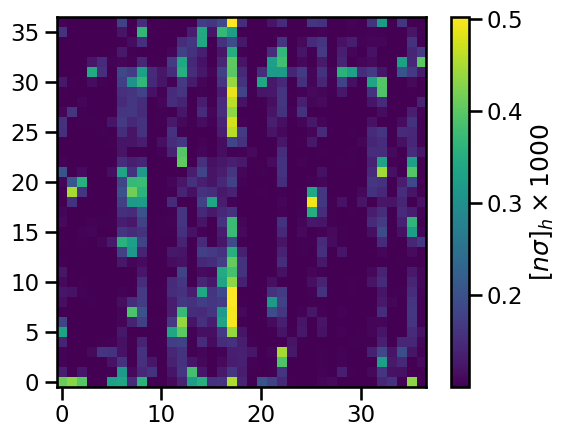

In [115]:
eprod_map = np.zeros(centroid_diff_map.shape)
hprod_map = np.zeros(centroid_diff_map.shape)

for i in range(37):
    for j in range(37):
        ediff_obs = centroid_diff_map_spline_e(i,j)
        hdiff_obs = centroid_diff_map_spline_h(i,j)
        def distance(eprod, hprod):
            return np.square(ediff_obs - ediff_interp((eprod, hprod))) + np.square(hdiff_obs - hdiff_interp((eprod, hprod)))
        m = Minuit(distance, eprod=1.0, hprod=0.5)
        m.fixed['eprod'] = True
        m.limits['hprod']=(np.min(hprod_grid), np.max(hprod_grid))
        m.migrad()
        # m.hesse()

        hprod_map[i,j] = m.values['hprod']
        print('p ' + str(i) + ' n ' +str(j) + ' ' + str(eprod_map_preLL[i,j]) + ' ' + str(m.values['hprod']) + '\n')

    
plt.figure()
plt.imshow(hprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{h} \times 1000$')
plt.savefig(plot_dir + 'postLL/trapping_prod_map_holes_etrapfixed.pdf')

In [117]:
print("Mean [nσe]-1 = ", np.mean(eprod_map)*1000, "Mean [nσh]-1 = ", np.mean(hprod_map - hprod_map)*1000)
print("Standard deviation in [nσe]-1 = ", np.std(eprod_map)*1000, "Standard deviation in [nσh]-1 = ", np.std(hprod_map)*1000)

Mean [nσe]-1 =  0.0 Mean [nσh]-1 =  0.0
Standard deviation in [nσe]-1 =  0.0 Standard deviation in [nσh]-1 =  72.39789431927547


p 0 n 0 1.1204939647678127 0.4315512885023301

p 0 n 1 1.1204692791130866 0.17340803658457457

p 0 n 2 1.120834680161618 0.101521896837447

p 0 n 3 1.1208334930759674 0.10525098760926016

p 0 n 4 1.1208214936384389 0.1930957819444376

p 0 n 5 1.1062101714216612 0.3150392407958813

p 0 n 6 1.1206579617600745 0.30812908544372664

p 0 n 7 1.1208293168487213 0.18104833509767282

p 0 n 8 1.120835086427752 0.10027868404230617

p 0 n 9 1.1209242510962587 0.10076119134394024

p 0 n 10 1.1214808206261897 0.12226136827410983

p 0 n 11 1.1208343356946442 0.16779980034861514

p 0 n 12 1.120864835660826 0.12787560471543888

p 0 n 13 1.12092282212183 0.10000388642571219

p 0 n 14 1.1208333341476342 0.10055525617550251

p 0 n 15 1.120830929248985 0.10002179290856078

p 0 n 16 1.120938888083437 0.10017293684787995

p 0 n 17 1.1208334351445521 0.1001163676171216

p 0 n 18 1.1211896061183109 0.10207723401862935

p 0 n 19 1.120833619415523 0.10372068674134693

p 0 n 20 1.120833272217565 0.104765310759748

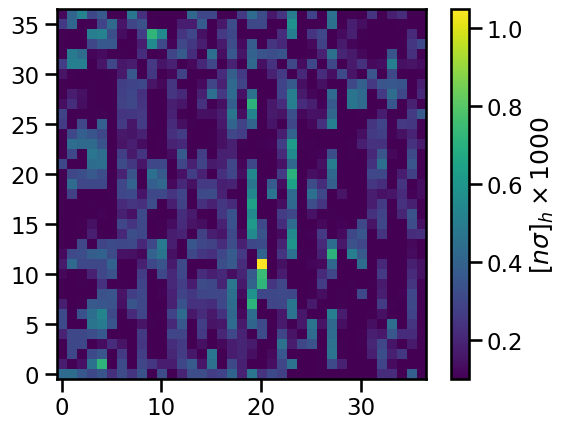

In [118]:
eprod_map = np.zeros(centroid_diff_map.shape)
hprod_map = np.zeros(centroid_diff_map.shape)

with open('/Users/Sophie/Desktop/COSI/calibrations/Data/HP41520_trappingprodmap.txt', 'w') as file:
    
    for i in range(37):
        for j in range(37):
            ediff_obs = centroid_diff_map_spline_e(i,j)
            hdiff_obs = centroid_diff_map_spline_h(i,j)
            def distance(eprod, hprod):
                return np.square(ediff_obs - ediff_interp((eprod, hprod))) + np.square(hdiff_obs - hdiff_interp((eprod, hprod)))
            # print(eprod_map_preLL[i,j])
            m = Minuit(distance, eprod=eprod_map_preLL[i,j], hprod=1.0)
            m.fixed['eprod'] = True
            m.limits['hprod']=(np.min(hprod_grid), np.max(hprod_grid))
            # print(np.min(hprod_grid), np.max(hprod_grid))
            m.migrad()
            # m.hesse()
    
            hprod_map[i,j] = m.values['hprod']

            file.write('p ' + str(i) + ' n ' +str(j) + ' ' + str(eprod_map_preLL[i,j]) + ' ' + str(m.values['hprod']) + '\n')
            print('p ' + str(i) + ' n ' +str(j) + ' ' + str(eprod_map_preLL[i,j]) + ' ' + str(m.values['hprod']) + '\n')
plt.figure()
plt.imshow(hprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{h} \times 1000$')
plt.savefig(plot_dir + 'postLL/trapping_prod_map_holes_etrapfixedtopreLL.pdf')
print("Mean [nσe]-1 = ", np.mean(eprod_map)*1000, "Mean [nσh]-1 = ", np.mean(hprod_map)*1000)
print("Standard deviation in [nσe]-1 = ", np.std(eprod_map)*1000, "Standard deviation in [nσh]-1 = ", np.std(hprod_map)*1000)

p 0 n 0 1.1204939647678127 0.3624805335642653

p 0 n 1 1.1204692791130866 0.19540383917215745

p 0 n 2 1.120834680161618 0.10000000000005141

p 0 n 3 1.1208334930759674 0.10000000000004271

p 0 n 4 1.1208214936384389 0.20425510613446132

p 0 n 5 1.1062101714216612 0.315115374609486

p 0 n 6 1.1206579617600745 0.3057896531830457

p 0 n 7 1.1208293168487213 0.18019059200098633

p 0 n 8 1.120835086427752 0.10000000000142667

p 0 n 9 1.1209242510962587 0.10000000000045071

p 0 n 10 1.1214808206261897 0.12312289288688072

p 0 n 11 1.1208343356946442 0.16852134681233102

p 0 n 12 1.120864835660826 0.1285659641179668

p 0 n 13 1.12092282212183 0.10000000000002802

p 0 n 14 1.1208333341476342 0.10000000000000789

p 0 n 15 1.120830929248985 0.10000000000002231

p 0 n 16 1.120938888083437 0.100000000009243

p 0 n 17 1.1208334351445521 0.10000000061385328

p 0 n 18 1.1211896061183109 0.10000000000008596

p 0 n 19 1.120833619415523 0.10000000000003428

p 0 n 20 1.120833272217565 0.1154428995259345

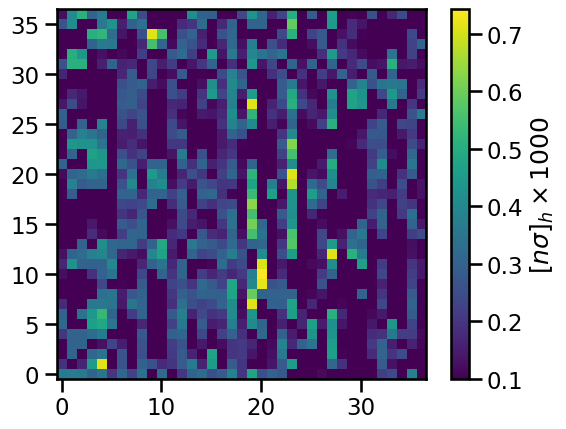

In [119]:
eprod_map = np.zeros(centroid_diff_map.shape)
hprod_map = np.zeros(centroid_diff_map.shape)

with open('/Users/Sophie/Desktop/COSI/calibrations/Data/HP41520_trappingprodmap.txt', 'w') as file:
    
    for i in range(37):
        for j in range(37):
            ediff_obs = centroid_diff_map_spline_e(i,j)
            hdiff_obs = centroid_diff_map_spline_h(i,j)
            def distance(eprod, hprod):
                return np.square(ediff_obs - ediff_interp((eprod, hprod))) + np.square(hdiff_obs - hdiff_interp((eprod, hprod)))
            # print(eprod_map_preLL[i,j])
            m = Minuit(distance, eprod=eprod_map_preLL[i,j], hprod=0.032)
            m.fixed['eprod'] = True
            m.limits['hprod']=(np.min(hprod_grid), np.max(hprod_grid))
            # print(np.min(hprod_grid), np.max(hprod_grid))
            m.migrad()
            # m.hesse()
    
            hprod_map[i,j] = m.values['hprod']

            file.write('p ' + str(i) + ' n ' +str(j) + ' ' + str(eprod_map_preLL[i,j]) + ' ' + str(m.values['hprod']) + '\n')
            print('p ' + str(i) + ' n ' +str(j) + ' ' + str(eprod_map_preLL[i,j]) + ' ' + str(m.values['hprod']) + '\n')
plt.figure()
plt.imshow(hprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{h} \times 1000$')
plt.savefig(plot_dir + 'postLL/trapping_prod_map_holes_etrapfixedtopreLL.pdf')
print("Mean [nσe]-1 = ", np.mean(eprod_map)*1000, "Mean [nσh]-1 = ", np.mean(hprod_map)*1000)
print("Standard deviation in [nσe]-1 = ", np.std(eprod_map)*1000, "Standard deviation in [nσh]-1 = ", np.std(hprod_map)*1000)

# Filter out non-positive values to prevent log errors
eprod_map = eprod_map_preLL
print(np.mean(eprod_map_preLL))
eprod_valid = eprod_map[eprod_map > 0]
hprod_valid = hprod_map[hprod_map > 0]

# Calculate Geometric Mean (scaled by 1000 to match your units)
geom_mean_e = np.exp(np.mean(np.log(eprod_valid))) * 1000
geom_mean_h = np.exp(np.mean(np.log(hprod_valid))) * 1000

# Calculate Geometric Standard Deviation (multiplicative factor)
geom_std_e = np.exp(np.std(np.log(eprod_valid)))
geom_std_h = np.exp(np.std(np.log(hprod_valid)))

print(f"Geometric Mean [nσe]-1 = {geom_mean_e:.7f}  (GSTD factor = {geom_std_e:.3f})")
print(f"Geometric Mean [nσh]-1 = {geom_mean_h:.7f}  (GSTD factor = {geom_std_h:.3f})")

at_bound = np.isclose(hprod_map, np.min(hprod_grid)) | np.isclose(hprod_map, np.max(hprod_grid))
print('Pixels with hprod at the grid bounds: %d / %d' % (at_bound.sum(), at_bound.size))
eprod_on_node = np.isclose(eprod_map_preLL[..., None], eprod_grid[None, None, :], atol=1e-3).any(axis=-1)
print('Pixels with pre-LL eprod sitting on a grid node: %d / %d' % (eprod_on_node.sum(), eprod_on_node.size))

p 0 n 0 1.1204939647678127 0.1

p 0 n 1 1.1204692791130866 0.1

p 0 n 2 1.120834680161618 0.1

p 0 n 3 1.1208334930759674 0.1

p 0 n 4 1.1208214936384389 0.1

p 0 n 5 1.1062101714216612 0.1

p 0 n 6 1.1206579617600745 0.1

p 0 n 7 1.1208293168487213 0.1

p 0 n 8 1.120835086427752 0.1

p 0 n 9 1.1209242510962587 0.1

p 0 n 10 1.1214808206261897 0.1

p 0 n 11 1.1208343356946442 0.1

p 0 n 12 1.120864835660826 0.1

p 0 n 13 1.12092282212183 0.1

p 0 n 14 1.1208333341476342 0.1

p 0 n 15 1.120830929248985 0.1

p 0 n 16 1.120938888083437 0.1

p 0 n 17 1.1208334351445521 0.1

p 0 n 18 1.1211896061183109 0.1

p 0 n 19 1.120833619415523 0.1

p 0 n 20 1.120833272217565 0.1

p 0 n 21 1.1205486101509614 0.1

p 0 n 22 1.1208617635897582 0.1

p 0 n 23 1.1208334777554534 0.1

p 0 n 24 1.1209389488643422 0.1

p 0 n 25 1.1208308578206476 0.1

p 0 n 26 1.1208230804759611 0.1

p 0 n 27 1.1208313738906055 0.1

p 0 n 28 1.1223398242502536 0.1

p 0 n 29 1.1208538778459425 0.1

p 0 n 30 1.1201387888289438 0

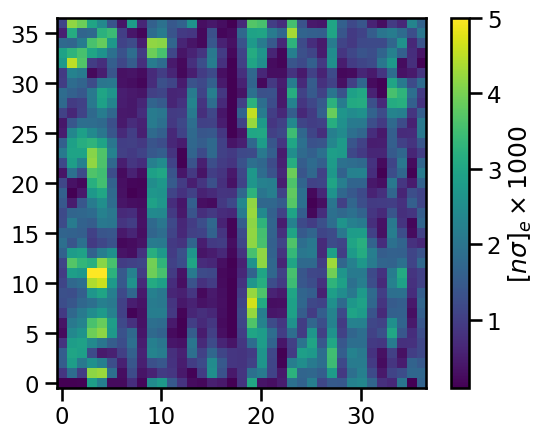

In [120]:
eprod_map = np.zeros(centroid_diff_map.shape)
hprod_map = np.zeros(centroid_diff_map.shape)

for i in range(37):
    for j in range(37):
        ediff_obs = centroid_diff_map_spline_e(i,j)
        hdiff_obs = centroid_diff_map_spline_h(i,j)
        def distance(eprod, hprod):
            return np.square(ediff_obs - ediff_interp((eprod, hprod))) + np.square(hdiff_obs - hdiff_interp((eprod, hprod)))
        m = Minuit(distance, eprod=np.min(eprod_grid), hprod=np.min(hprod_grid))
        m.limits['eprod']=(np.min(eprod_grid), np.max(eprod_grid))
        m.fixed['hprod'] = True
        m.migrad()
        # m.hesse()

        eprod_map[i,j] = m.values['eprod']
        hprod_map[i,j] = m.values['hprod']
        print('p ' + str(i) + ' n ' +str(j) + ' ' + str(eprod_map_preLL[i,j]) + ' ' + str(m.values['hprod']) + '\n')

    
plt.figure()
plt.imshow(eprod_map.T, origin='lower')
plt.colorbar(label=r'$[n\sigma]_{e} \times 1000$')
plt.savefig(plot_dir + 'postLL/trapping_prod_map_electrons_htrapfixed.pdf')
print("Mean [nσe]-1 = ", np.mean(eprod_map)*1000, "Mean [nσh]-1 = ", np.mean(hprod_map)*1000)
print("Standard deviation in [nσe]-1 = ", np.std(eprod_map)*1000, "Standard deviation in [nσh]-1 = ", np.std(hprod_map)*1000)